## 셋업 — 경로 + 파일 존재 확인

In [2]:
import json
import cv2
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 경로 (필요 시 수정)
ROOT = Path(r"D:\pill_detection")
RESULTS_JSON = ROOT / "eval" / "rtmdet_tiny_synth_e15_seed100_results.json"  # 실제 위치 다르면 수정
TEST_IMAGES = ROOT / "eval" / "test_images"
TEST_LABELS = ROOT / "eval" / "test_labels" / "test_labels"

# 존재 확인
print("results.json:", RESULTS_JSON.exists(), "→", RESULTS_JSON)
print("test_images :", TEST_IMAGES.exists(),
      f"({len(list(TEST_IMAGES.glob('*'))) if TEST_IMAGES.exists() else 0} files)")
print("test_labels :", TEST_LABELS.exists(),
      f"({len(list(TEST_LABELS.glob('*'))) if TEST_LABELS.exists() else 0} files)")

results.json: True → D:\pill_detection\eval\rtmdet_tiny_synth_e15_seed100_results.json
test_images : True (33 files)
test_labels : True (33 files)


## results.json + test_labels 구조 확인

In [3]:
# 1. results.json 구조
with open(RESULTS_JSON, "r", encoding="utf-8") as f:
    results = json.load(f)

print("=" * 60)
print("results.json")
print("=" * 60)
print(f"type: {type(results).__name__}")
if isinstance(results, dict):
    print(f"top-level keys: {list(results.keys())}")
    # 첫 키 1개 샘플
    first_key = list(results.keys())[0]
    print(f"\nfirst key: {first_key!r}")
    print(f"first value type: {type(results[first_key]).__name__}")
    print(f"first value sample:")
    print(json.dumps(results[first_key], ensure_ascii=False, indent=2)[:800])
elif isinstance(results, list):
    print(f"length: {len(results)}")
    print(f"first item:")
    print(json.dumps(results[0], ensure_ascii=False, indent=2)[:800])

# 2. test_labels 첫 파일
print("\n" + "=" * 60)
print("test_labels — 첫 파일")
print("=" * 60)
label_files = sorted(TEST_LABELS.glob("*"))
first_label = label_files[0]
print(f"file: {first_label.name}")
print(f"extension: {first_label.suffix}")
with open(first_label, "r", encoding="utf-8") as f:
    content = f.read()
print(f"content (first 500 chars):")
print(content[:500])

results.json
type: dict
top-level keys: ['exp_name', 'author', 'model_framework', 'model_params_M', 'batch_size_used', 'seed', 'conf_threshold', 'nms_iou', 'best_epoch', 'ms_per_image', 'eval_version', 'num_images', 'num_gt_bboxes', 'created_at', 'results']

first key: 'exp_name'
first value type: str
first value sample:
"rtmdet_tiny_synth_e15_seed100"

test_labels — 첫 파일
file: 게보린정 300mg_3.txt
extension: .txt
content (first 500 chars):
1 0.509843 0.496259 0.562992 0.349127



## results 본문 + 라벨 클래스 매핑 확인

In [4]:
# 1. results 본문 구조
print("=" * 60)
print("results['results'] 구조")
print("=" * 60)
res = results['results']
print(f"type: {type(res).__name__}")

if isinstance(res, list):
    print(f"length: {len(res)}")
    print(f"\nfirst item:")
    print(json.dumps(res[0], ensure_ascii=False, indent=2)[:1500])
elif isinstance(res, dict):
    print(f"keys (first 5): {list(res.keys())[:5]}")
    first_key = list(res.keys())[0]
    print(f"\nfirst key: {first_key!r}")
    print(json.dumps(res[first_key], ensure_ascii=False, indent=2)[:1500])

# 2. 메타 정보 정리
print("\n" + "=" * 60)
print("실험 메타")
print("=" * 60)
for k in ['exp_name', 'best_epoch', 'conf_threshold', 'nms_iou',
          'num_images', 'num_gt_bboxes', 'eval_version', 'seed']:
    if k in results:
        print(f"  {k}: {results[k]}")

# 3. 라벨 파일 전체 라인 수 (총 ann 개수 확인)
print("\n" + "=" * 60)
print("라벨 통계")
print("=" * 60)
total_ann = 0
class_ids = []
for lf in sorted(TEST_LABELS.glob("*.txt")):
    with open(lf, "r", encoding="utf-8") as f:
        lines = [l for l in f.read().strip().split("\n") if l.strip()]
    total_ann += len(lines)
    for line in lines:
        class_ids.append(int(line.split()[0]))

print(f"총 라벨 파일: {len(list(TEST_LABELS.glob('*.txt')))}")
print(f"총 ann 수: {total_ann}")
print(f"등장 클래스 수: {len(set(class_ids))}")
print(f"클래스 ID 범위: {min(class_ids)} ~ {max(class_ids)}")
print(f"클래스별 등장 횟수 (상위 10):")
print(pd.Series(class_ids).value_counts().head(10))

results['results'] 구조
type: list
length: 33

first item:
{
  "filename": "게보린정 300mg_3.png",
  "gt_bboxes": [
    {
      "bbox": [
        58.00013800000001,
        128.9998955,
        201.00010600000002,
        268.9998225
      ],
      "dl_name": "게보린정 300mg/PTP"
    }
  ],
  "predictions": [
    {
      "bbox": [
        50.16144943237305,
        120.20346069335938,
        209.27362060546875,
        273.9439697265625
      ],
      "top3_class_name": [
        "게보린정 300mg/PTP",
        "동아가바펜틴정 800mg",
        "제미메트서방정 50/1000mg"
      ],
      "top3_confidence": [
        0.9332519769668579,
        0.15733246505260468,
        0.12934119999408722
      ]
    },
    {
      "bbox": [
        0.0,
        0.0,
        210.3436737060547,
        244.1102752685547
      ],
      "top3_class_name": [
        "트라젠타듀오정 2.5/850mg",
        "자누메트정 50/850mg"
      ],
      "top3_confidence": [
        0.08761126548051834,
        0.06086853891611099
      ]
    },
    {
      "bbox"

## GT ↔ 예측 매칭 (IoU 0.5, 0.3 둘 다)

각 GT마다 IoU 최대인 예측 1개 매칭. 두 임계값으로 각각 매칭해서 비교.

판정 카테고리:
- **Top-1 정답**: 매칭된 예측의 top3[0]이 GT dl_name과 일치
- **Top-3 정답**: top3 안에 dl_name 있음 (Top-1은 아닐 수 있음)
- **Detection만**: 매칭은 됨, top3 안에 정답 없음
- **Detection 실패**: 매칭되는 예측 없음

In [5]:
def iou_xyxy(box1, box2):
    """두 xyxy 박스의 IoU"""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    if x2 <= x1 or y2 <= y1:
        return 0.0
    inter = (x2 - x1) * (y2 - y1)
    a1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    a2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = a1 + a2 - inter
    return inter / union if union > 0 else 0.0


def match_gt_to_pred(gt_bboxes, predictions, iou_thr):
    """
    각 GT마다 IoU 최대인 예측 1개 매칭 (IoU >= iou_thr).
    한 예측은 한 GT에만 매칭 (greedy, IoU 높은 GT 우선).
    
    Returns:
        gt_matches: [{gt_idx, pred_idx, iou, gt_name, top3_names, top3_conf, verdict}]
        unmatched_pred_idx: 매칭 안 된 예측 인덱스 (오탐)
    """
    n_gt = len(gt_bboxes)
    n_pred = len(predictions)
    
    # IoU 매트릭스
    iou_mat = np.zeros((n_gt, n_pred))
    for i, gt in enumerate(gt_bboxes):
        for j, pred in enumerate(predictions):
            iou_mat[i, j] = iou_xyxy(gt['bbox'], pred['bbox'])
    
    # Greedy 매칭: 가장 IoU 높은 GT-Pred 쌍부터 매칭
    gt_matches = []
    used_pred = set()
    used_gt = set()
    
    # 모든 (gt, pred) 쌍을 IoU 내림차순 정렬
    pairs = [(iou_mat[i, j], i, j) for i in range(n_gt) for j in range(n_pred)]
    pairs.sort(reverse=True)
    
    for iou, i, j in pairs:
        if iou < iou_thr:
            break
        if i in used_gt or j in used_pred:
            continue
        used_gt.add(i)
        used_pred.add(j)
        
        gt_name = gt_bboxes[i]['dl_name']
        top3_names = predictions[j].get('top3_class_name', [])
        top3_conf = predictions[j].get('top3_confidence', [])
        
        # 판정
        if len(top3_names) > 0 and top3_names[0] == gt_name:
            verdict = 'top1'
        elif gt_name in top3_names:
            verdict = 'top3'
        else:
            verdict = 'det_only'
        
        gt_matches.append({
            'gt_idx': i, 'pred_idx': j, 'iou': iou,
            'gt_name': gt_name, 'top3_names': top3_names, 'top3_conf': top3_conf,
            'verdict': verdict
        })
    
    # 매칭 안 된 GT (Detection 실패)
    for i in range(n_gt):
        if i not in used_gt:
            gt_matches.append({
                'gt_idx': i, 'pred_idx': None, 'iou': 0.0,
                'gt_name': gt_bboxes[i]['dl_name'],
                'top3_names': [], 'top3_conf': [],
                'verdict': 'det_fail'
            })
    
    unmatched_pred_idx = [j for j in range(n_pred) if j not in used_pred]
    return gt_matches, unmatched_pred_idx


# 두 임계값으로 전체 매칭
def run_matching(iou_thr):
    rows = []
    fp_count = 0
    for img_data in results['results']:
        fname = img_data['filename']
        gts = img_data['gt_bboxes']
        preds = img_data['predictions']
        
        matches, unmatched_preds = match_gt_to_pred(gts, preds, iou_thr)
        fp_count += len(unmatched_preds)
        
        for m in matches:
            rows.append({
                'filename': fname,
                'gt_idx': m['gt_idx'],
                'gt_name': m['gt_name'],
                'pred_idx': m['pred_idx'],
                'iou': m['iou'],
                'verdict': m['verdict'],
                'top1_pred': m['top3_names'][0] if m['top3_names'] else None,
                'top3_names': m['top3_names'],
                'top1_conf': m['top3_conf'][0] if m['top3_conf'] else None,
            })
    return pd.DataFrame(rows), fp_count


df_05, fp_05 = run_matching(0.5)
df_03, fp_03 = run_matching(0.3)

# 요약
print("=" * 60)
print("매칭 결과 요약 (47 GT 기준)")
print("=" * 60)
summary = pd.DataFrame({
    'IoU≥0.5': df_05['verdict'].value_counts(),
    'IoU≥0.3': df_03['verdict'].value_counts(),
}).fillna(0).astype(int)
summary.loc['total'] = summary.sum()
print(summary)

print(f"\n오탐 (매칭 안 된 예측):")
print(f"  IoU≥0.5: {fp_05}")
print(f"  IoU≥0.3: {fp_03}")

print(f"\nTop-1 / Top-3 정답률:")
for thr, df in [(0.5, df_05), (0.3, df_03)]:
    n = len(df)
    n_top1 = (df['verdict'] == 'top1').sum()
    n_top3 = df['verdict'].isin(['top1', 'top3']).sum()
    n_det = df['verdict'].isin(['top1', 'top3', 'det_only']).sum()
    print(f"  IoU≥{thr}: Top-1 {n_top1}/{n} ({n_top1/n*100:.1f}%) / "
          f"Top-3 {n_top3}/{n} ({n_top3/n*100:.1f}%) / "
          f"Detection {n_det}/{n} ({n_det/n*100:.1f}%)")

# df 저장 (다음 셀에서 사용)
df_05.head()

매칭 결과 요약 (47 GT 기준)
          IoU≥0.5  IoU≥0.3
verdict                   
det_only       26       27
top1           14       14
top3            5        5
det_fail        2        1
total          47       47

오탐 (매칭 안 된 예측):
  IoU≥0.5: 259
  IoU≥0.3: 258

Top-1 / Top-3 정답률:
  IoU≥0.5: Top-1 14/47 (29.8%) / Top-3 19/47 (40.4%) / Detection 45/47 (95.7%)
  IoU≥0.3: Top-1 14/47 (29.8%) / Top-3 19/47 (40.4%) / Detection 46/47 (97.9%)


,filename,gt_idx,gt_name,pred_idx,iou,verdict,top1_pred,top3_names,top1_conf
0,게보린정 300mg_3.png,0,게보린정 300mg/PTP,0.0,0.818412,top1,게보린정 300mg/PTP,"[게보린정 300mg/PTP, 동아가바펜틴정 800mg, 제미메트서방정 50/100...",0.933252
1,글리아타민연질캡슐.png,0,글리아타민연질캡슐,0.0,0.900025,det_only,놀텍정 10mg,"[놀텍정 10mg, 이가탄에프캡슐 150mg/PTP, 엔테론정 150mg]",0.562592
2,낙소졸정 500_20mg.png,0,낙소졸정 500/20mg,2.0,0.910051,det_only,엔테론정 150mg,"[엔테론정 150mg, 비모보정 500/20mg, 엘스테인정(에르도스테인)]",0.283222
3,넥시움정 40mg.png,0,넥시움정 40mg,0.0,0.885304,det_only,제미메트서방정 50/1000mg,"[제미메트서방정 50/1000mg, 낙소졸정 500/20mg, 비타비백정 100mg/병]",0.857662
4,노바스크정 5mg.png,0,노바스크정 5mg,0.0,0.886454,top1,노바스크정 5mg,"[노바스크정 5mg, 프로스카정, 아빌리파이정 10mg]",0.876541


## 33장 결과 그리드 — 큰 그림 보기

색상:
- 🟢 초록 = GT 박스
- 🔵 파랑 = Top-1 정답
- 🟠 주황 = Top-3 정답 (Top-1 틀림)
- 🔴 빨강 = Detection만 성공 (분류 실패)
- 🟢 점선 = Detection 실패 GT (예측 박스 없음)

오탐(259개)은 이 시각화에서 제외 — 별도 셀에서 분석.

In [7]:
import matplotlib.font_manager as fm

# Windows 한글 폰트 후보 (있는 것 자동 선택)
candidates = ['Malgun Gothic', 'NanumGothic', 'Gulim', 'Dotum', 'Batang']
available = {f.name for f in fm.fontManager.ttflist}
chosen = next((c for c in candidates if c in available), None)

if chosen:
    plt.rcParams['font.family'] = chosen
    plt.rcParams['axes.unicode_minus'] = False
    print(f"한글 폰트 설정: {chosen}")
else:
    print("한글 폰트 못 찾음. 다음 후보 중 설치된 것 확인 필요:")
    print(candidates)
    print(f"\n설치된 폰트 일부 (확인용):")
    print([f for f in sorted(available) if 'goth' in f.lower() or 'gulim' in f.lower() or 'malgun' in f.lower()][:10])

한글 폰트 설정: Malgun Gothic


저장: D:\pill_detection\analysis\figures\01_grid_33images.png


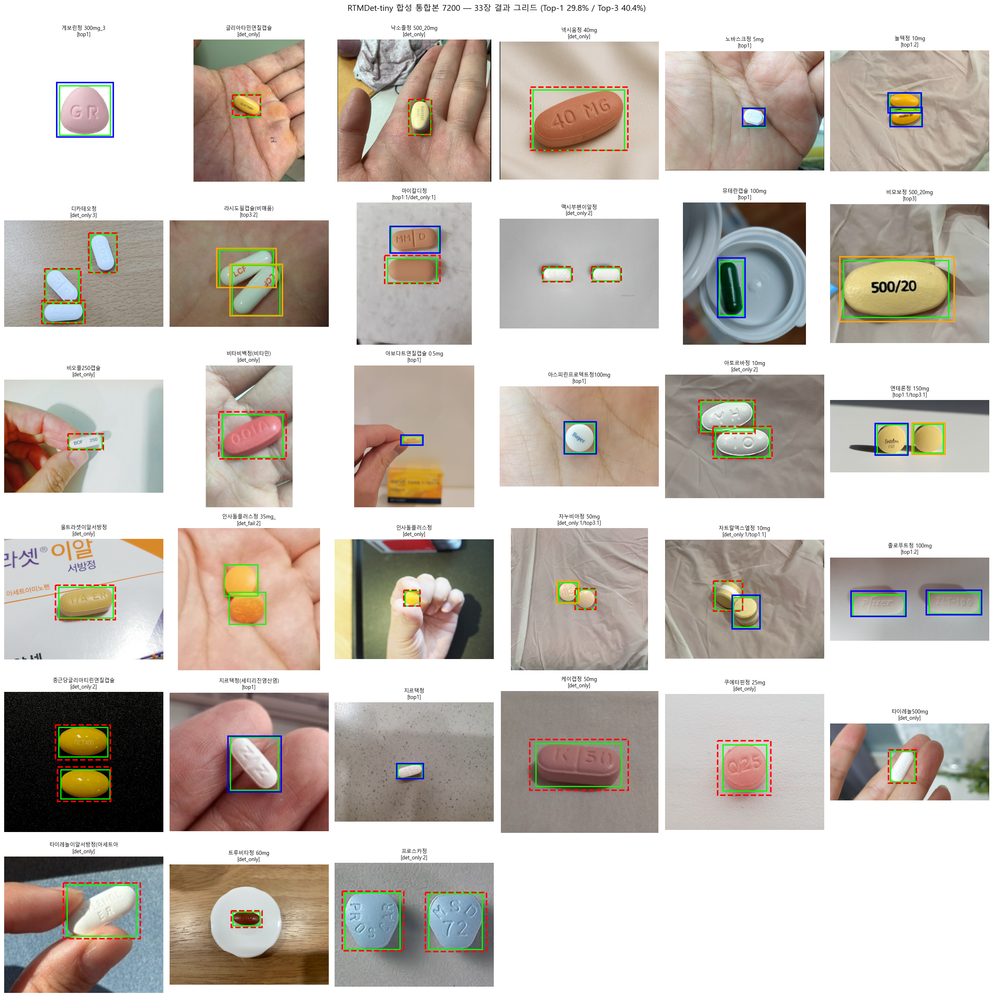

In [10]:
def imread_kr(path):
    """한글 경로 호환 imread"""
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


# 33장 → 6x6 그리드
n_imgs = len(results['results'])
ncols = 6
nrows = (n_imgs + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(24, 4 * nrows))
axes = axes.flatten()

for ax_idx, img_data in enumerate(results['results']):
    ax = axes[ax_idx]
    fname = img_data['filename']
    img_path = TEST_IMAGES / fname
    
    img = imread_kr(img_path)  # ← 여기만 수정
    if img is None:
        ax.text(0.5, 0.5, f"이미지 로드 실패\n{fname}",
                ha='center', va='center', transform=ax.transAxes)
        ax.axis('off')
        continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    
    # GT 박스 (초록 실선)
    for gt in img_data['gt_bboxes']:
        x1, y1, x2, y2 = gt['bbox']
        rect = Rectangle((x1, y1), x2 - x1, y2 - y1,
                         linewidth=2, edgecolor='lime', facecolor='none')
        ax.add_patch(rect)
    
    # 매칭된 예측 박스 (verdict별 색상)
    file_matches = matches_by_file.get(fname, pd.DataFrame())
    verdicts_this = []
    for _, row in file_matches.iterrows():
        verdicts_this.append(row['verdict'])
        if row['verdict'] == 'det_fail' or row['pred_idx'] is None:
            continue
        pred = img_data['predictions'][int(row['pred_idx'])]
        x1, y1, x2, y2 = pred['bbox']
        color = VERDICT_COLOR[row['verdict']]
        rect = Rectangle((x1, y1), x2 - x1, y2 - y1,
                         linewidth=2.5, edgecolor=color, facecolor='none',
                         linestyle='--' if row['verdict'] == 'det_only' else '-')
        ax.add_patch(rect)
    
    short_name = fname.replace('.png', '')[:14]
    if len(verdicts_this) == 1:
        v_summary = verdicts_this[0]
    else:
        from collections import Counter
        c = Counter(verdicts_this)
        v_summary = "/".join(f"{k}:{v}" for k, v in c.items())
    ax.set_title(f"{short_name}\n[{v_summary}]", fontsize=9)
    ax.axis('off')

for i in range(n_imgs, len(axes)):
    axes[i].axis('off')

plt.suptitle("RTMDet-tiny 합성 통합본 7200 — 33장 결과 그리드 (Top-1 29.8% / Top-3 40.4%)",
             fontsize=14, y=1.00)
plt.tight_layout()

out_path = ROOT / "analysis" / "figures" / "01_grid_33images.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()

## D2 — 예측 박스 중심 분포 (격자 외우기 가설 직접 검증)

비교:
- K-code train: 4모서리 격자 (확정)
- 합성 통합본 모델 예측 박스 (33장): 어디에 박스 치는지
- Test GT: 중앙 집중 (확정)

판정:
- 예측 박스가 4모서리에 쏠림 → 격자 외우기 확정
- 균일/중앙 분포 → 격자 외우기 부정

K-code train 라벨 로딩...
  K-code 라벨 파일: 8302, 박스: 31844

예측 박스 중심 추출...
  전체 예측: 304
  매칭된 예측 (TP): 45
  오탐 (FP): 259

Test GT 박스 중심 추출...
  Test GT: 47

저장: D:\pill_detection\analysis\figures\02_pred_center_distribution.png


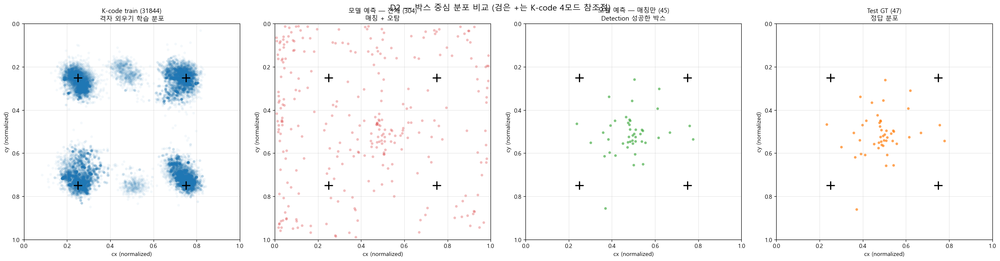


K-code 4모드 근처 (반경 0.12) 비율
  K-code train             : 28836/31844 ( 90.6%)
  모델 예측 (전체)               :    16/  304 (  5.3%)
  모델 예측 (매칭만)              :     0/   45 (  0.0%)
  모델 예측 (오탐만)              :    16/  259 (  6.2%)
  Test GT                  :     0/   47 (  0.0%)


In [11]:
KCODE_LABELS = ROOT / "data" / "dataset_yolo" / "labels" / "train"

# 1. K-code train 박스 중심 (YOLO 포맷: cx cy w h normalized)
print("K-code train 라벨 로딩...")
kcode_centers = []
kcode_files = list(KCODE_LABELS.glob("*.txt"))
for lf in kcode_files:
    with open(lf, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                kcode_centers.append((float(parts[1]), float(parts[2])))
print(f"  K-code 라벨 파일: {len(kcode_files)}, 박스: {len(kcode_centers)}")

# 2. 합성 통합본 모델 예측 박스 중심 (정규화 위해 이미지 크기 필요)
print("\n예측 박스 중심 추출...")
pred_all_centers = []      # 모든 예측
pred_matched_centers = []  # 매칭된 예측만
pred_fp_centers = []       # 오탐만

# 매칭된 pred_idx 빠르게 찾기 위해 set 만들기
matched_pred_set = set()  # (filename, pred_idx) 튜플
for _, row in df_05.iterrows():
    if row['pred_idx'] is not None and not pd.isna(row['pred_idx']):
        matched_pred_set.add((row['filename'], int(row['pred_idx'])))

for img_data in results['results']:
    fname = img_data['filename']
    img = imread_kr(TEST_IMAGES / fname)
    if img is None:
        continue
    H, W = img.shape[:2]
    for j, pred in enumerate(img_data['predictions']):
        x1, y1, x2, y2 = pred['bbox']
        cx = (x1 + x2) / 2 / W
        cy = (y1 + y2) / 2 / H
        pred_all_centers.append((cx, cy))
        if (fname, j) in matched_pred_set:
            pred_matched_centers.append((cx, cy))
        else:
            pred_fp_centers.append((cx, cy))

print(f"  전체 예측: {len(pred_all_centers)}")
print(f"  매칭된 예측 (TP): {len(pred_matched_centers)}")
print(f"  오탐 (FP): {len(pred_fp_centers)}")

# 3. Test GT 박스 중심
print("\nTest GT 박스 중심 추출...")
test_gt_centers = []
for img_data in results['results']:
    fname = img_data['filename']
    img = imread_kr(TEST_IMAGES / fname)
    if img is None:
        continue
    H, W = img.shape[:2]
    for gt in img_data['gt_bboxes']:
        x1, y1, x2, y2 = gt['bbox']
        test_gt_centers.append(((x1 + x2) / 2 / W, (y1 + y2) / 2 / H))
print(f"  Test GT: {len(test_gt_centers)}")

# 4. 시각화 (4 subplot)
fig, axes = plt.subplots(1, 4, figsize=(24, 6))

datasets = [
    (kcode_centers, f"K-code train ({len(kcode_centers)})\n격자 외우기 학습 분포", 'tab:blue', 0.05),
    (pred_all_centers, f"모델 예측 — 전체 ({len(pred_all_centers)})\n매칭 + 오탐", 'tab:red', 0.3),
    (pred_matched_centers, f"모델 예측 — 매칭만 ({len(pred_matched_centers)})\nDetection 성공한 박스", 'tab:green', 0.6),
    (test_gt_centers, f"Test GT ({len(test_gt_centers)})\n정답 분포", 'tab:orange', 0.7),
]

for ax, (data, title, color, alpha) in zip(axes, datasets):
    if data:
        xs, ys = zip(*data)
        ax.scatter(xs, ys, alpha=alpha, s=20, c=color, edgecolors='none')
    
    # K-code 4모드 위치 참조선
    for mx in [0.25, 0.75]:
        for my in [0.25, 0.75]:
            ax.scatter(mx, my, marker='+', s=200, c='black', linewidths=2, zorder=10)
    
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)  # 이미지 좌표 (위가 0)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('cx (normalized)')
    ax.set_ylabel('cy (normalized)')
    ax.grid(True, alpha=0.3)

plt.suptitle("D2 — 박스 중심 분포 비교 (검은 +는 K-code 4모드 참조점)", fontsize=14)
plt.tight_layout()

out_path = ROOT / "analysis" / "figures" / "02_pred_center_distribution.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 5. 정량 — 예측 박스 중 K-code 4모드 근처(반경 0.12) 비율
def near_4mode(centers, radius=0.12):
    if not centers: return 0, 0
    centers_arr = np.array(centers)
    near = 0
    for mx in [0.25, 0.75]:
        for my in [0.25, 0.75]:
            dist = np.sqrt((centers_arr[:, 0] - mx)**2 + (centers_arr[:, 1] - my)**2)
            near += (dist < radius).sum()
    return near, len(centers)

print("\n" + "=" * 60)
print("K-code 4모드 근처 (반경 0.12) 비율")
print("=" * 60)
for name, data in [
    ("K-code train", kcode_centers),
    ("모델 예측 (전체)", pred_all_centers),
    ("모델 예측 (매칭만)", pred_matched_centers),
    ("모델 예측 (오탐만)", pred_fp_centers),
    ("Test GT", test_gt_centers),
]:
    near, total = near_4mode(data)
    pct = near / total * 100 if total else 0
    print(f"  {name:25s}: {near:5d}/{total:5d} ({pct:5.1f}%)")

## D3 — bbox 크기 × 정답률

목적: Test GT 박스 크기 구간별 정답률 측정 + Test 분포 자체 파악.

이전 가설 ("합성 -3~-5 / Test -1~-2 → 합성 알약 너무 작음")은 측정 오류로 정정됨. 양질/신규 합성 정규화 면적 평균은 모두 log -1.23으로 Test 평균(-1.23)과 동일. 진짜 차별점은 평균이 아니라 분포 폭(std):
- 양질 1800: std 0.586 (다양함)
- 신규 5400: std 0.251 (좁음)
- Test 33장: std 0.355
- K-code 학습: std 0.252

→ 합성이 알약 크기를 좁은 범위에 몰아넣어 학습 다양성이 부족.

GT 박스 크기 통계 (이미지 대비 비율):
count    47.000000
mean      0.079828
std       0.062983
min       0.010152
25%       0.031255
50%       0.064873
75%       0.090681
max       0.272019
Name: rel_area, dtype: float64

log10 area 범위: -1.99 ~ -0.57

저장: D:\pill_detection\analysis\figures\03_bbox_size_vs_verdict.png


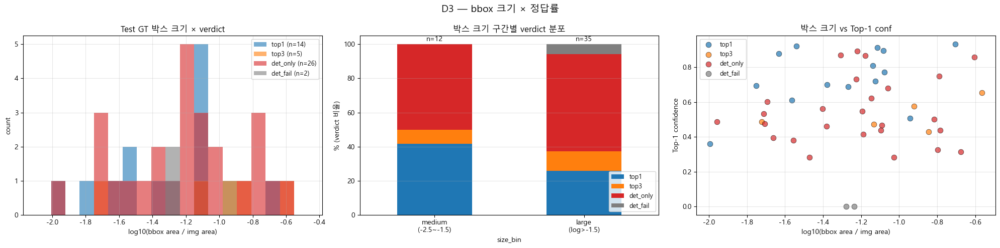


크기 구간별 Top-1 / Top-3 / Detection 정답률
  medium
(-2.5~-1.5)   n= 12 | Top-1 5/12 ( 41.7%) | Top-3 6/12 ( 50.0%) | Det 12/12 (100.0%)
  large
(log>-1.5)     n= 35 | Top-1 9/35 ( 25.7%) | Top-3 13/35 ( 37.1%) | Det 33/35 ( 94.3%)


In [31]:
# Test GT 박스 크기 (이미지 대비 정규화 area) 계산 + verdict 매칭
gt_size_records = []
img_size_cache = {}

for img_data in results['results']:
    fname = img_data['filename']
    if fname not in img_size_cache:
        img = imread_kr(TEST_IMAGES / fname)
        img_size_cache[fname] = img.shape[:2] if img is not None else (1, 1)
    H, W = img_size_cache[fname]
    img_area = H * W
    
    for gt_idx, gt in enumerate(img_data['gt_bboxes']):
        x1, y1, x2, y2 = gt['bbox']
        bbox_area = (x2 - x1) * (y2 - y1)
        rel_area = bbox_area / img_area  # 이미지 대비 비율
        
        # df_05에서 해당 GT의 verdict 찾기
        match = df_05[(df_05['filename'] == fname) & (df_05['gt_idx'] == gt_idx)]
        verdict = match['verdict'].iloc[0] if len(match) else 'unknown'
        
        gt_size_records.append({
            'filename': fname,
            'gt_idx': gt_idx,
            'gt_name': gt['dl_name'],
            'rel_area': rel_area,
            'log_area': np.log10(rel_area) if rel_area > 0 else np.nan,
            'verdict': verdict,
        })

df_size = pd.DataFrame(gt_size_records)
print(f"GT 박스 크기 통계 (이미지 대비 비율):")
print(df_size['rel_area'].describe())
print(f"\nlog10 area 범위: {df_size['log_area'].min():.2f} ~ {df_size['log_area'].max():.2f}")

# 시각화 1: log area 분포 + verdict
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# (1) Test GT log area histogram (verdict별 색)
ax = axes[0]
verdict_order = ['top1', 'top3', 'det_only', 'det_fail']
verdict_colors = {'top1': 'tab:blue', 'top3': 'tab:orange', 'det_only': 'tab:red', 'det_fail': 'tab:gray'}
bins = np.linspace(df_size['log_area'].min() - 0.1, df_size['log_area'].max() + 0.1, 20)

for v in verdict_order:
    sub = df_size[df_size['verdict'] == v]['log_area']
    if len(sub):
        ax.hist(sub, bins=bins, alpha=0.6, label=f"{v} (n={len(sub)})", color=verdict_colors[v])
# 합성 분포 영역 표시
ax.set_xlabel('log10(bbox area / img area)')
ax.set_ylabel('count')
ax.set_title('Test GT 박스 크기 × verdict')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# (2) 크기 구간별 정답률 (3구간)
ax = axes[1]
df_size['size_bin'] = pd.cut(df_size['log_area'],
                              bins=[-np.inf, -2.5, -1.5, np.inf],
                              labels=['small\n(log<-2.5)', 'medium\n(-2.5~-1.5)', 'large\n(log>-1.5)'])
ct = pd.crosstab(df_size['size_bin'], df_size['verdict'], normalize='index') * 100
ct = ct.reindex(columns=verdict_order, fill_value=0)
ct.plot(kind='bar', stacked=True, ax=ax,
        color=[verdict_colors[v] for v in verdict_order])
ax.set_ylabel('% (verdict 비율)')
ax.set_title('박스 크기 구간별 verdict 분포')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
# 구간별 n 표시
for i, b in enumerate(ct.index):
    n = (df_size['size_bin'] == b).sum()
    ax.text(i, 102, f"n={n}", ha='center', fontsize=10)
ax.legend(fontsize=9, loc='lower right')
ax.grid(axis='y', alpha=0.3)

# (3) scatter: log_area vs Top-1 conf
ax = axes[2]
df_size_with_conf = df_size.merge(df_05[['filename', 'gt_idx', 'top1_conf']],
                                    on=['filename', 'gt_idx'], how='left')
for v in verdict_order:
    sub = df_size_with_conf[df_size_with_conf['verdict'] == v]
    ax.scatter(sub['log_area'], sub['top1_conf'].fillna(0),
               c=verdict_colors[v], alpha=0.7, s=60, label=v, edgecolors='k', linewidth=0.5)
ax.set_xlabel('log10(bbox area / img area)')
ax.set_ylabel('Top-1 confidence')
ax.set_title('박스 크기 vs Top-1 conf')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.suptitle("D3 — bbox 크기 × 정답률", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "03_bbox_size_vs_verdict.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 — 크기 구간별 정답률 표
print("\n" + "=" * 60)
print("크기 구간별 Top-1 / Top-3 / Detection 정답률")
print("=" * 60)
for b in ct.index:
    sub = df_size[df_size['size_bin'] == b]
    n = len(sub)
    top1 = (sub['verdict'] == 'top1').sum()
    top3 = sub['verdict'].isin(['top1', 'top3']).sum()
    det = sub['verdict'].isin(['top1', 'top3', 'det_only']).sum()
    print(f"  {str(b):20s} n={n:3d} | Top-1 {top1}/{n} ({top1/n*100:5.1f}%) | "
          f"Top-3 {top3}/{n} ({top3/n*100:5.1f}%) | Det {det}/{n} ({det/n*100:5.1f}%)")

## D4 — 이미지 내 알약 개수별 성능

목적: 이미지 내 알약 개수별로 모델 성능 측정 + 합성 학습 분포 파악.

합성 통합본의 알약 개수 분포는 평균 2.88개 (1개 비율 3.4%, 4개 비중 29%). Test 분포(평균 1.42개, 1개 60.6%)와 다르며, 더 본질적으로는 **합성이 1개 알약 케이스를 거의 학습 안 시킴**.

검증:
- 33장을 GT 개수별로 분류
- 개수별 Top-1/Top-3 정답률
- 다중 알약 이미지에서 실패 양상

해석 관점: Test 매칭 갭이 아니라 **학습 분포 다양성**으로 본다. 모델이 1개 케이스를 학습 못 하면 처음 보는 단일 알약 시나리오에서 작동 못 함.

이미지별 GT 개수 분포:
n_gt
1    20
2    12
3     1
Name: count, dtype: int64

총 이미지: 33, 평균 GT/장: 1.42
세션 37 박제 Test 평균: 1.42 / 실측: 1.42

저장: D:\pill_detection\analysis\figures\04_pill_count_vs_verdict.png


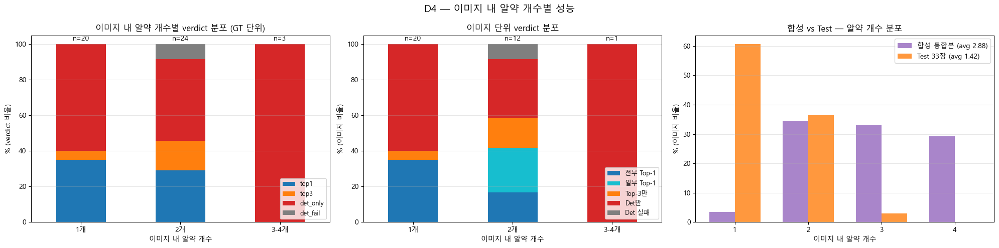


이미지 내 알약 개수별 정답률 (GT 단위)
  1개       n= 20 | Top-1 7/20 ( 35.0%) | Top-3 8/20 ( 40.0%) | Det 20/20 (100.0%)
  2개       n= 24 | Top-1 7/24 ( 29.2%) | Top-3 11/24 ( 45.8%) | Det 22/24 ( 91.7%)
  3-4개     n=  3 | Top-1 0/3 (  0.0%) | Top-3 0/3 (  0.0%) | Det 3/3 (100.0%)

이미지 단위 verdict 분포
img_verdict  Det 실패  Det만  Top-3만  일부 Top-1  전부 Top-1
n_gt_bin                                             
1개                0    12       1         0         7
2개                1     4       2         3         2
3-4개              0     1       0         0         0


In [13]:
# 이미지별 GT 개수 + verdict 집계
img_records = []
for img_data in results['results']:
    fname = img_data['filename']
    n_gt = len(img_data['gt_bboxes'])
    
    # 이 이미지의 모든 GT verdict
    file_matches = df_05[df_05['filename'] == fname]
    verdicts = file_matches['verdict'].tolist()
    
    n_top1 = sum(v == 'top1' for v in verdicts)
    n_top3 = sum(v in ['top1', 'top3'] for v in verdicts)
    n_det = sum(v in ['top1', 'top3', 'det_only'] for v in verdicts)
    
    img_records.append({
        'filename': fname,
        'n_gt': n_gt,
        'n_top1': n_top1,
        'n_top3': n_top3,
        'n_det': n_det,
    })

df_img = pd.DataFrame(img_records)
print("이미지별 GT 개수 분포:")
print(df_img['n_gt'].value_counts().sort_index())
print(f"\n총 이미지: {len(df_img)}, 평균 GT/장: {df_img['n_gt'].mean():.2f}")

# Test 평균 1.42 박제값 vs 실제 매칭
print(f"세션 37 박제 Test 평균: 1.42 / 실측: {df_img['n_gt'].mean():.2f}")

# 시각화 1: 개수 구간별 정답률
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# (1) 개수별 GT 단위 정답률 (47개 GT 기준)
ax = axes[0]
df_size_with_n_gt = df_size.merge(df_img[['filename', 'n_gt']], on='filename')
df_size_with_n_gt['n_gt_bin'] = df_size_with_n_gt['n_gt'].apply(
    lambda x: '1개' if x == 1 else ('2개' if x == 2 else '3-4개'))

ct = pd.crosstab(df_size_with_n_gt['n_gt_bin'], df_size_with_n_gt['verdict'], normalize='index') * 100
ct = ct.reindex(index=['1개', '2개', '3-4개'], columns=['top1', 'top3', 'det_only', 'det_fail'], fill_value=0)
ct.plot(kind='bar', stacked=True, ax=ax,
        color=['tab:blue', 'tab:orange', 'tab:red', 'tab:gray'])
ax.set_ylabel('% (verdict 비율)')
ax.set_xlabel('이미지 내 알약 개수')
ax.set_title('이미지 내 알약 개수별 verdict 분포 (GT 단위)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, b in enumerate(ct.index):
    n = (df_size_with_n_gt['n_gt_bin'] == b).sum()
    ax.text(i, 102, f"n={n}", ha='center', fontsize=10)
ax.legend(fontsize=9, loc='lower right')
ax.grid(axis='y', alpha=0.3)

# (2) 이미지 단위 — 다 맞춤/일부 맞춤/다 틀림
ax = axes[1]
def img_verdict(row):
    if row['n_top1'] == row['n_gt']:
        return '전부 Top-1'
    elif row['n_top1'] > 0:
        return '일부 Top-1'
    elif row['n_top3'] > 0:
        return 'Top-3만'
    elif row['n_det'] > 0:
        return 'Det만'
    else:
        return 'Det 실패'
df_img['img_verdict'] = df_img.apply(img_verdict, axis=1)
df_img['n_gt_bin'] = df_img['n_gt'].apply(
    lambda x: '1개' if x == 1 else ('2개' if x == 2 else '3-4개'))

ct2 = pd.crosstab(df_img['n_gt_bin'], df_img['img_verdict'], normalize='index') * 100
order = ['전부 Top-1', '일부 Top-1', 'Top-3만', 'Det만', 'Det 실패']
ct2 = ct2.reindex(index=['1개', '2개', '3-4개'], columns=order, fill_value=0)
ct2.plot(kind='bar', stacked=True, ax=ax,
         color=['tab:blue', 'tab:cyan', 'tab:orange', 'tab:red', 'tab:gray'])
ax.set_ylabel('% (이미지 비율)')
ax.set_xlabel('이미지 내 알약 개수')
ax.set_title('이미지 단위 verdict 분포')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, b in enumerate(ct2.index):
    n = (df_img['n_gt_bin'] == b).sum()
    ax.text(i, 102, f"n={n}", ha='center', fontsize=10)
ax.legend(fontsize=9, loc='lower right')
ax.grid(axis='y', alpha=0.3)

# (3) 합성 vs Test 알약 개수 분포 비교
ax = axes[2]
synth_dist = {1: 3.4, 2: 34.4, 3: 33.0, 4: 29.3}  # 세션 37 박제값
test_dist = df_img['n_gt'].value_counts(normalize=True).sort_index() * 100

x = np.arange(1, 5)
synth_vals = [synth_dist.get(i, 0) for i in x]
test_vals = [test_dist.get(i, 0) for i in x]

w = 0.35
ax.bar(x - w/2, synth_vals, w, label=f"합성 통합본 (avg 2.88)", color='tab:purple', alpha=0.8)
ax.bar(x + w/2, test_vals, w, label=f"Test 33장 (avg {df_img['n_gt'].mean():.2f})", color='tab:orange', alpha=0.8)
ax.set_xticks(x)
ax.set_xlabel('이미지 내 알약 개수')
ax.set_ylabel('% (이미지 비율)')
ax.set_title('합성 vs Test — 알약 개수 분포')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.suptitle("D4 — 이미지 내 알약 개수별 성능", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "04_pill_count_vs_verdict.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 표
print("\n" + "=" * 60)
print("이미지 내 알약 개수별 정답률 (GT 단위)")
print("=" * 60)
for b in ['1개', '2개', '3-4개']:
    sub = df_size_with_n_gt[df_size_with_n_gt['n_gt_bin'] == b]
    n = len(sub)
    if n == 0: continue
    top1 = (sub['verdict'] == 'top1').sum()
    top3 = sub['verdict'].isin(['top1', 'top3']).sum()
    det = sub['verdict'].isin(['top1', 'top3', 'det_only']).sum()
    print(f"  {b:8s} n={n:3d} | Top-1 {top1}/{n} ({top1/n*100:5.1f}%) | "
          f"Top-3 {top3}/{n} ({top3/n*100:5.1f}%) | Det {det}/{n} ({det/n*100:5.1f}%)")

print("\n" + "=" * 60)
print("이미지 단위 verdict 분포")
print("=" * 60)
print(df_img.groupby('n_gt_bin')['img_verdict'].value_counts().unstack(fill_value=0))

## C — 환경별 성능 (수동 라벨링)

33장을 직접 보고 환경 카테고리 입력. 그리드(`01_grid_33images.png`) 참고.

카테고리:
- `palm`: 손바닥/손가락
- `desk`: 책상/테이블 (단단한 표면)
- `cloth`: 천/이불/옷
- `paper`: 흰 종이/벽
- `bottle`: 약통/뚜껑
- `box`: 박스/포장
- `dark`: 검은 배경/극단 어두움
- `other`: 기타

In [14]:
# 33장 파일명 + 라벨링 템플릿 출력
print("# 환경 라벨링 템플릿 — 아래 dict 복사해서 다음 셀에 붙여넣기")
print()
print("env_labels = {")
for img_data in results['results']:
    fname = img_data['filename']
    n_gt = len(img_data['gt_bboxes'])
    print(f"    {fname!r}: '',  # n_gt={n_gt}")
print("}")
print()
print("# 카테고리: palm / desk / cloth / paper / bottle / box / dark / other")

# 환경 라벨링 템플릿 — 아래 dict 복사해서 다음 셀에 붙여넣기

env_labels = {
    '게보린정 300mg_3.png': '',  # n_gt=1
    '글리아타민연질캡슐.png': '',  # n_gt=1
    '낙소졸정 500_20mg.png': '',  # n_gt=1
    '넥시움정 40mg.png': '',  # n_gt=1
    '노바스크정 5mg.png': '',  # n_gt=1
    '놀텍정 10mg.png': '',  # n_gt=2
    '디카테오정.png': '',  # n_gt=3
    '라시도필캡슐(비매품).png': '',  # n_gt=2
    '마이칼디정.png': '',  # n_gt=2
    '맥시부펜이알정.png': '',  # n_gt=2
    '뮤테란캡슐 100mg.png': '',  # n_gt=1
    '비모보정 500_20mg.png': '',  # n_gt=1
    '비오플250캡슐.png': '',  # n_gt=1
    '비타비백정(비타민).png': '',  # n_gt=1
    '아보다트연질캡슐 0.5mg_1.png': '',  # n_gt=1
    '아스피린프로텍트정100mg.png': '',  # n_gt=1
    '아토르바정 10mg.png': '',  # n_gt=2
    '엔테론정 150mg.png': '',  # n_gt=2
    '울트라셋이알서방정.png': '',  # n_gt=1
    '인사돌플러스정 35mg_.png': '',  # n_gt=2
    '인사돌플러스정.png': '',  # n_gt=1
    '자누비아정 50mg.png': '',  # n_gt=2
    '자트랄엑스엘정 10mg.png': '',  # n_gt=2
    '졸로푸트정 100mg.png': '',  # n_gt=2
    '종근당글리아티린연질캡슐.png': '',  # n_gt=2
    '지르텍정(세티리진염산염).png': '',  # n_gt=1
  

라벨 OK: 33장

환경 분포:
palm      15
cloth      6
paper      4
desk       4
bottle     2
box        1
dark       1
Name: count, dtype: int64

저장: D:\pill_detection\analysis\figures\05_env_vs_verdict.png


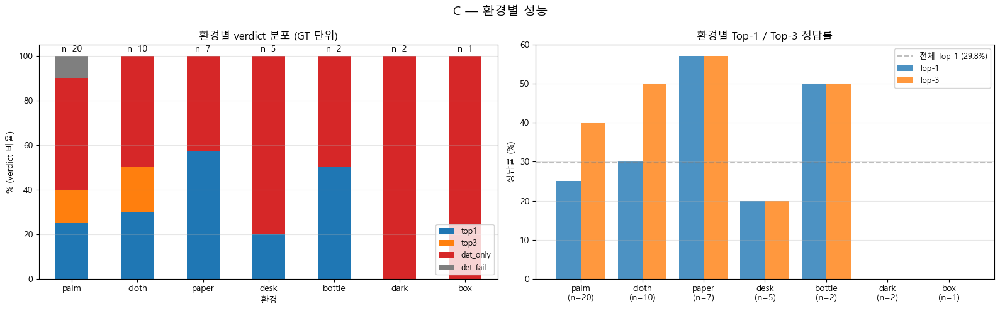


환경별 정답률 (GT 단위)
  palm     n= 20 | Top-1 5/20 ( 25.0%) | Top-3 8/20 ( 40.0%) | Det 18/20 ( 90.0%)
  cloth    n= 10 | Top-1 3/10 ( 30.0%) | Top-3 5/10 ( 50.0%) | Det 10/10 (100.0%)
  paper    n=  7 | Top-1 4/7 ( 57.1%) | Top-3 4/7 ( 57.1%) | Det 7/7 (100.0%)
  desk     n=  5 | Top-1 1/5 ( 20.0%) | Top-3 1/5 ( 20.0%) | Det 5/5 (100.0%)
  bottle   n=  2 | Top-1 1/2 ( 50.0%) | Top-3 1/2 ( 50.0%) | Det 2/2 (100.0%)
  dark     n=  2 | Top-1 0/2 (  0.0%) | Top-3 0/2 (  0.0%) | Det 2/2 (100.0%)
  box      n=  1 | Top-1 0/1 (  0.0%) | Top-3 0/1 (  0.0%) | Det 1/1 (100.0%)


In [15]:
env_labels = {
    '게보린정 300mg_3.png': 'paper',
    '글리아타민연질캡슐.png': 'palm',
    '낙소졸정 500_20mg.png': 'palm',
    '넥시움정 40mg.png': 'cloth',
    '노바스크정 5mg.png': 'cloth',
    '놀텍정 10mg.png': 'palm',
    '디카테오정.png': 'palm',
    '라시도필캡슐(비매품).png': 'palm',
    '마이칼디정.png': 'paper',
    '맥시부펜이알정.png': 'paper',
    '뮤테란캡슐 100mg.png': 'bottle',
    '비모보정 500_20mg.png': 'palm',
    '비오플250캡슐.png': 'palm',
    '비타비백정(비타민).png': 'palm',
    '아보다트연질캡슐 0.5mg_1.png': 'palm',
    '아스피린프로텍트정100mg.png': 'palm',
    '아토르바정 10mg.png': 'cloth',
    '엔테론정 150mg.png': 'cloth',
    '울트라셋이알서방정.png': 'box',
    '인사돌플러스정 35mg_.png': 'palm',
    '인사돌플러스정.png': 'palm',
    '자누비아정 50mg.png': 'cloth',
    '자트랄엑스엘정 10mg.png': 'cloth',
    '졸로푸트정 100mg.png': 'paper',
    '종근당글리아티린연질캡슐.png': 'dark',
    '지르텍정(세티리진염산염).png': 'palm',
    '지르텍정.png': 'desk',
    '케이캡정 50mg.png': 'desk',
    '쿠에타핀정 25mg.png': 'desk',
    '타이레놀500mg.png': 'palm',
    '타이레놀이알서방정(아세트아미노펜)(수출용).png': 'palm',
    '트루비타정 60mg.png': 'bottle',
    '프로스카정.png': 'desk',
}

# 라벨 검증
missing = set(df_05['filename']) - set(env_labels.keys())
extra = set(env_labels.keys()) - set(df_05['filename'])
assert not missing and not extra, f"missing={missing}, extra={extra}"
print(f"라벨 OK: {len(env_labels)}장")
print(f"\n환경 분포:")
print(pd.Series(list(env_labels.values())).value_counts())

# df_05에 환경 라벨 붙이기
df_env = df_05.copy()
df_env['env'] = df_env['filename'].map(env_labels)

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (1) 환경 × verdict
ax = axes[0]
env_order = ['palm', 'cloth', 'paper', 'desk', 'bottle', 'dark', 'box']
env_order = [e for e in env_order if e in df_env['env'].unique()]
ct = pd.crosstab(df_env['env'], df_env['verdict'], normalize='index') * 100
ct = ct.reindex(index=env_order, columns=['top1', 'top3', 'det_only', 'det_fail'], fill_value=0)
ct.plot(kind='bar', stacked=True, ax=ax,
        color=['tab:blue', 'tab:orange', 'tab:red', 'tab:gray'])
ax.set_ylabel('% (verdict 비율)')
ax.set_xlabel('환경')
ax.set_title('환경별 verdict 분포 (GT 단위)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, e in enumerate(ct.index):
    n = (df_env['env'] == e).sum()
    ax.text(i, 102, f"n={n}", ha='center', fontsize=10)
ax.legend(fontsize=9, loc='lower right')
ax.grid(axis='y', alpha=0.3)

# (2) 환경별 Top-1 정답률 막대
ax = axes[1]
env_acc = []
for e in env_order:
    sub = df_env[df_env['env'] == e]
    n = len(sub)
    top1 = (sub['verdict'] == 'top1').sum()
    top3 = sub['verdict'].isin(['top1', 'top3']).sum()
    env_acc.append({'env': e, 'n': n, 'top1_pct': top1/n*100, 'top3_pct': top3/n*100})
env_df = pd.DataFrame(env_acc)

x = np.arange(len(env_df))
w = 0.4
ax.bar(x - w/2, env_df['top1_pct'], w, label='Top-1', color='tab:blue', alpha=0.8)
ax.bar(x + w/2, env_df['top3_pct'], w, label='Top-3', color='tab:orange', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"{e}\n(n={n})" for e, n in zip(env_df['env'], env_df['n'])])
ax.set_ylabel('정답률 (%)')
ax.set_title('환경별 Top-1 / Top-3 정답률')
ax.axhline(29.8, ls='--', color='gray', alpha=0.5, label='전체 Top-1 (29.8%)')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.suptitle("C — 환경별 성능", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "05_env_vs_verdict.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 표
print("\n" + "=" * 60)
print("환경별 정답률 (GT 단위)")
print("=" * 60)
for e in env_order:
    sub = df_env[df_env['env'] == e]
    n = len(sub)
    top1 = (sub['verdict'] == 'top1').sum()
    top3 = sub['verdict'].isin(['top1', 'top3']).sum()
    det = sub['verdict'].isin(['top1', 'top3', 'det_only']).sum()
    print(f"  {e:8s} n={n:3d} | Top-1 {top1}/{n} ({top1/n*100:5.1f}%) | "
          f"Top-3 {top3}/{n} ({top3/n*100:5.1f}%) | Det {det}/{n} ({det/n*100:5.1f}%)")

In [16]:
# K-code 학습 데이터 구조 확인
KCODE_IMAGES = ROOT / "data" / "dataset_yolo" / "images" / "train"
print(f"K-code train images: {KCODE_IMAGES.exists()}")
print(f"파일 수: {len(list(KCODE_IMAGES.glob('*'))) if KCODE_IMAGES.exists() else 'N/A'}")

# 파일명 샘플 5개
print(f"\n파일명 샘플 (앞 10개):")
for f in sorted(KCODE_IMAGES.glob('*'))[:10]:
    print(f"  {f.name}")

# 파일명 패턴 분석 — 클래스명 어떻게 박혀있나
print(f"\n파일명에서 dl_name 매칭 가능한지 확인...")
# Test의 dl_name 1개 가져와서 K-code 이미지에서 찾을 수 있나
test_dl = "게보린정 300mg/PTP"
# / 는 파일명에 못 쓰니 변형 가능성 검토
candidates = []
for f in KCODE_IMAGES.glob('*'):
    if '게보린' in f.name:
        candidates.append(f.name)
        if len(candidates) >= 5:
            break
print(f"  '게보린' 포함 파일: {candidates}")

# clean_df.csv 있으면 거기서 매핑 정보
clean_df_path = ROOT / "data" / "team_preprocessed" / "clean_df.csv"
print(f"\nclean_df.csv: {clean_df_path.exists()}")
if clean_df_path.exists():
    cdf = pd.read_csv(clean_df_path, nrows=3)
    print(f"컬럼: {list(cdf.columns)}")
    print(cdf.head(3))

K-code train images: True
파일 수: 8302

파일명 샘플 (앞 10개):
  K-000250-000573-002483-012778_0_2_0_2_75_000_200.png
  K-000250-000573-002483-012778_0_2_0_2_90_000_200.png
  K-000250-000573-002483-019552_0_2_0_2_70_000_200.png
  K-000250-000573-002483-019552_0_2_0_2_75_000_200.png
  K-000250-000573-002483-019552_0_2_0_2_90_000_200.png
  K-000250-000573-002483-022627_0_2_0_2_70_000_200.png
  K-000250-000573-002483-022627_0_2_0_2_75_000_200.png
  K-000250-000573-002483-022627_0_2_0_2_90_000_200.png
  K-000250-000573-002483-023223_0_2_0_2_70_000_200.png
  K-000250-000573-002483-023223_0_2_0_2_75_000_200.png

파일명에서 dl_name 매칭 가능한지 확인...
  '게보린' 포함 파일: []

clean_df.csv: True
컬럼: ['file_name', 'image_id', 'width', 'height', 'category_id', 'dl_name', 'dl_name_en', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'area', 'color_class1', 'color_class2', 'drug_shape', 'print_front', 'print_back', 'form_code_name', 'di_etc_otc_code', 'camera_la', 'leng_long', 'leng_short', 'thick', 'class_idx', 'class_name', 'bbo

In [19]:
KCODE_IMAGES_VAL = ROOT / "data" / "dataset_yolo" / "images" / "val"
print(f"K-code val: {KCODE_IMAGES_VAL.exists()}, "
      f"파일 수: {len(list(KCODE_IMAGES_VAL.glob('*'))) if KCODE_IMAGES_VAL.exists() else 0}")

# train + val 실제 존재 파일 set
train_files = {f.name for f in KCODE_IMAGES.glob('*.png')}
val_files = {f.name for f in KCODE_IMAGES_VAL.glob('*.png')} if KCODE_IMAGES_VAL.exists() else set()
all_existing = train_files | val_files
print(f"실제 존재 파일 (train + val): {len(all_existing)}")

# clean_df에서 실제 존재 파일만 필터링 → dl_name별 첫 번째
cdf_exist = cdf[cdf['file_name'].isin(all_existing)].copy()
print(f"clean_df 중 실제 존재: {len(cdf_exist)}")

# 파일이 어느 폴더에 있는지 표시
def find_path(fname):
    if fname in train_files:
        return KCODE_IMAGES / fname
    elif fname in val_files:
        return KCODE_IMAGES_VAL / fname
    return None

samples_by_dl = cdf_exist.drop_duplicates(subset='dl_name', keep='first').set_index('dl_name')
samples_by_dl['full_path'] = samples_by_dl['file_name'].apply(find_path)
print(f"dl_name별 샘플: {len(samples_by_dl)}개")

# 검증 — 예측에 등장하는 모든 dl_name이 cover 되는지
pred_names_needed = set()
for _, row in df_05.iterrows():
    if row['top1_pred']:
        pred_names_needed.add(row['top1_pred'])
pred_names_needed |= set(df_05['gt_name'].unique())

missing = pred_names_needed - set(samples_by_dl.index)
print(f"\n필요한 dl_name {len(pred_names_needed)}개 중 누락: {len(missing)}")
if missing:
    print(f"  → {missing}")

K-code val: True, 파일 수: 2090
실제 존재 파일 (train + val): 10392
clean_df 중 실제 존재: 39864
dl_name별 샘플: 118개

필요한 dl_name 45개 중 누락: 0


## B + E2 — 분류 실패 케이스 풀비교 (혼동 패턴)

det_only 26개 케이스에서 GT 알약 ROI vs 모델이 본 Top-1 예측 클래스 ROI 나란히 비교.

판정:
- 진짜 비슷한 알약끼리 혼동인지
- 색·형태 자체가 다른 엉뚱한 혼동인지
- → 분류기가 시각 특징을 학습했는지 평가

det_only 케이스: 26개
저장: D:\pill_detection\analysis\figures\06_confusion_pairs.png


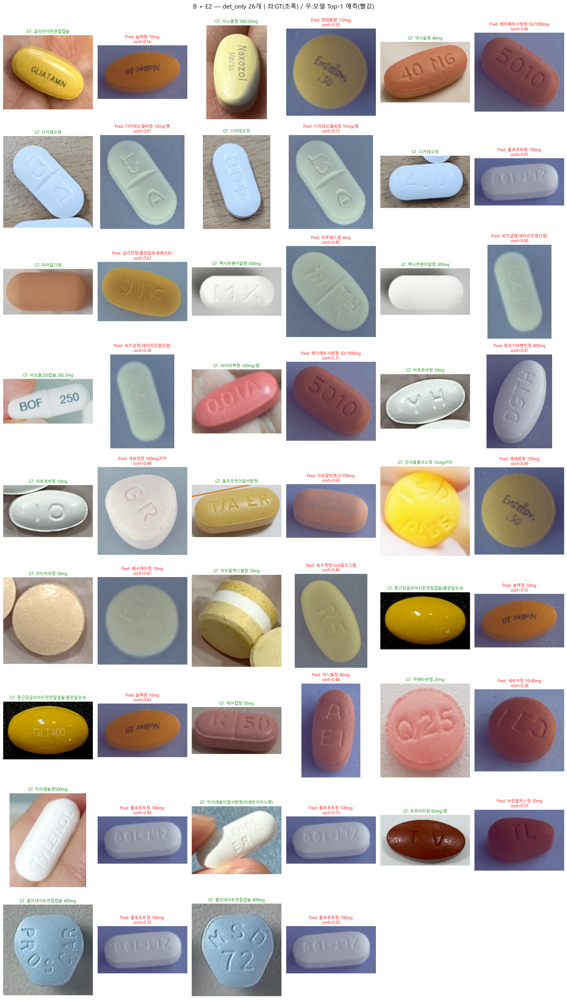


det_only 26개 — GT vs 예측
   1. 글리아타민연질캡슐                      → 놀텍정 10mg                       (conf=0.56)
   2. 낙소졸정 500/20mg                  → 엔테론정 150mg                     (conf=0.28)
   3. 넥시움정 40mg                      → 제미메트서방정 50/1000mg              (conf=0.86)
   4. 디카테오정                          → 디카테오엘씨정 10mg/병                 (conf=0.87)
   5. 디카테오정                          → 디카테오엘씨정 10mg/병                 (conf=0.73)
   6. 디카테오정                          → 졸로푸트정 100mg                    (conf=0.87)
   7. 마이칼디정                          → 글리틴정(콜린알포세레이트)                 (conf=0.62)
   8. 맥시부펜이알정 300mg                  → 트루패스정 4mg                      (conf=0.40)
   9. 맥시부펜이알정 300mg                  → 씨즈날정(세티리진염산염)                  (conf=0.60)
  10. 비오플250캡슐 282.5mg               → 씨즈날정(세티리진염산염)                  (conf=0.38)
  11. 비타비백정 100mg/병                  → 제미메트서방정 50/1000mg              (conf=0.31)
  12. 아토르바정 10mg                     → 동아가바펜틴정 800mg                  (co

In [21]:
det_only_cases = df_05[df_05['verdict'] == 'det_only'].reset_index(drop=True)
print(f"det_only 케이스: {len(det_only_cases)}개")

n_cases = len(det_only_cases)
n_grid_cols = 6
cases_per_row = 3
nrows = (n_cases + cases_per_row - 1) // cases_per_row

fig, axes = plt.subplots(nrows, n_grid_cols, figsize=(n_grid_cols * 3, nrows * 3.5))
if nrows == 1:
    axes = axes.reshape(1, -1)

for i, row in det_only_cases.iterrows():
    grid_row = i // cases_per_row
    grid_col_base = (i % cases_per_row) * 2
    
    # GT 알약 (Test)
    ax_gt = axes[grid_row, grid_col_base]
    fname = row['filename']
    img_data = next(d for d in results['results'] if d['filename'] == fname)
    gt_bbox = img_data['gt_bboxes'][int(row['gt_idx'])]['bbox']
    gt_roi = crop_test_roi(TEST_IMAGES / fname, gt_bbox)
    if gt_roi is not None:
        ax_gt.imshow(gt_roi)
    ax_gt.set_title(f"GT: {row['gt_name'][:18]}", fontsize=9, color='green')
    ax_gt.axis('off')
    
    # 예측 클래스 K-code 샘플
    ax_pred = axes[grid_row, grid_col_base + 1]
    pred_name = row['top1_pred']
    if pred_name in samples_by_dl.index:
        s = samples_by_dl.loc[pred_name]
        if s['full_path'] is not None:
            pred_roi = crop_pill_roi(
                s['full_path'],
                (s['bbox_x'], s['bbox_y'], s['bbox_w'], s['bbox_h'])
            )
            if pred_roi is not None:
                ax_pred.imshow(pred_roi)
    conf = row['top1_conf']
    ax_pred.set_title(f"Pred: {pred_name[:18]}\nconf={conf:.2f}", fontsize=9, color='red')
    ax_pred.axis('off')

for i in range(n_cases, nrows * cases_per_row):
    grid_row = i // cases_per_row
    grid_col_base = (i % cases_per_row) * 2
    axes[grid_row, grid_col_base].axis('off')
    axes[grid_row, grid_col_base + 1].axis('off')

plt.suptitle(f"B + E2 — det_only {n_cases}개 | 좌:GT(초록) / 우:모델 Top-1 예측(빨강)",
             fontsize=14, y=1.00)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "06_confusion_pairs.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()

print("\n" + "=" * 80)
print("det_only 26개 — GT vs 예측")
print("=" * 80)
for i, row in det_only_cases.iterrows():
    print(f"  {i+1:2d}. {row['gt_name']:30s} → {row['top1_pred']:30s} (conf={row['top1_conf']:.2f})")

## F — 오탐 259개 분석

D2에서 보인 "예측 박스 가장자리 쏠림" 정밀 분석.

검증:
- F1: 오탐 위치/크기 분포 (어디에 어떤 박스 치는지)
- F2: 오탐 패턴 분류 (배경/손가락/박스 모서리/중복 박스 등)
- F3: 오탐 conf 분포 (낮은 conf인지 높은 conf인지)

오탐 총 개수: 259
가장자리 오탐 (외곽 15%): 190 (73.4%)


C:\Users\user\AppData\Local\Temp\ipykernel_12264\2962183474.py:105: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([edge_fp, center_fp], labels=[f'가장자리\n(n={len(edge_fp)})', f'중앙\n(n={len(center_fp)})'])



저장: D:\pill_detection\analysis\figures\07_fp_analysis.png


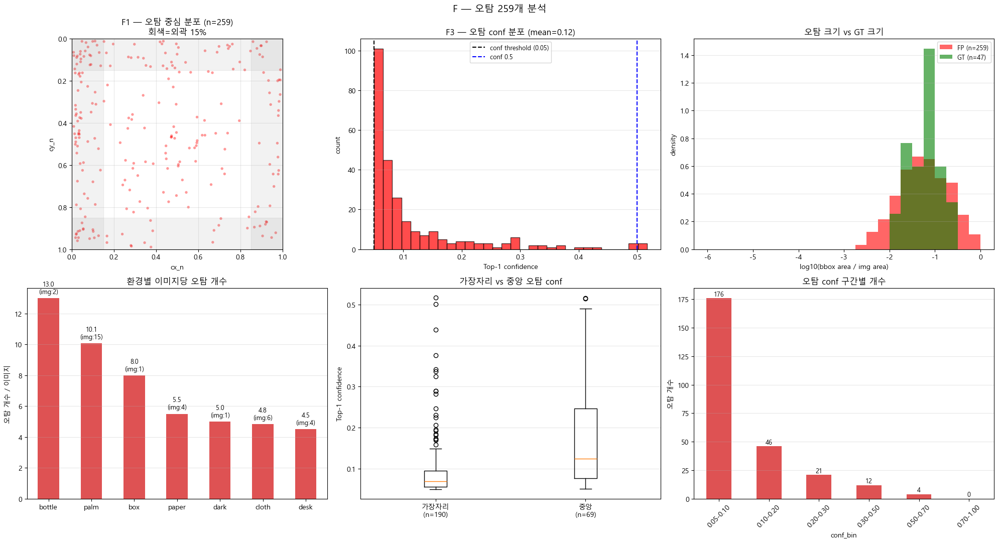


오탐 요약
  총 오탐: 259
  GT 대비 비율: 5.5배
  conf 평균: 0.116
  conf 0.5 이상 (높은 conf 오탐): 4
  가장자리 오탐: 190 (73.4%)
  log_area 평균 FP: -1.25 / GT: -1.23


In [22]:
# 오탐 정보 모으기 (매칭 안 된 예측 = FP)
matched_pred_set = set()
for _, row in df_05.iterrows():
    if row['pred_idx'] is not None and not pd.isna(row['pred_idx']):
        matched_pred_set.add((row['filename'], int(row['pred_idx'])))

fp_records = []
for img_data in results['results']:
    fname = img_data['filename']
    img = imread_kr(TEST_IMAGES / fname)
    if img is None:
        continue
    H, W = img.shape[:2]
    img_area = H * W
    
    for j, pred in enumerate(img_data['predictions']):
        if (fname, j) in matched_pred_set:
            continue  # TP는 제외
        x1, y1, x2, y2 = pred['bbox']
        bw = x2 - x1
        bh = y2 - y1
        cx_n = (x1 + x2) / 2 / W
        cy_n = (y1 + y2) / 2 / H
        rel_area = (bw * bh) / img_area
        top1_conf = pred['top3_confidence'][0] if pred.get('top3_confidence') else 0
        top1_pred = pred['top3_class_name'][0] if pred.get('top3_class_name') else None
        
        # 가장자리 여부 (중심이 외곽 15% 안)
        edge = (cx_n < 0.15 or cx_n > 0.85 or cy_n < 0.15 or cy_n > 0.85)
        
        fp_records.append({
            'filename': fname,
            'pred_idx': j,
            'cx_n': cx_n, 'cy_n': cy_n,
            'rel_area': rel_area,
            'log_area': np.log10(rel_area) if rel_area > 0 else np.nan,
            'top1_conf': top1_conf,
            'top1_pred': top1_pred,
            'edge': edge,
            'env': env_labels.get(fname, 'unknown'),
        })

df_fp = pd.DataFrame(fp_records)
print(f"오탐 총 개수: {len(df_fp)}")
print(f"가장자리 오탐 (외곽 15%): {df_fp['edge'].sum()} ({df_fp['edge'].mean()*100:.1f}%)")

# 시각화
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# (1) 오탐 중심 분포 (D2와 동일하지만 단독)
ax = axes[0, 0]
ax.scatter(df_fp['cx_n'], df_fp['cy_n'], alpha=0.4, s=15, c='red', edgecolors='none')
# 가장자리 영역 표시
ax.axhspan(0, 0.15, alpha=0.1, color='gray')
ax.axhspan(0.85, 1.0, alpha=0.1, color='gray')
ax.axvspan(0, 0.15, alpha=0.1, color='gray')
ax.axvspan(0.85, 1.0, alpha=0.1, color='gray')
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_aspect('equal')
ax.set_title(f"F1 — 오탐 중심 분포 (n={len(df_fp)})\n회색=외곽 15%")
ax.set_xlabel('cx_n'); ax.set_ylabel('cy_n')
ax.grid(alpha=0.3)

# (2) 오탐 conf 분포
ax = axes[0, 1]
ax.hist(df_fp['top1_conf'], bins=30, alpha=0.7, color='red', edgecolor='black')
ax.axvline(0.05, ls='--', color='black', label='conf threshold (0.05)')
ax.axvline(0.5, ls='--', color='blue', label='conf 0.5')
ax.set_xlabel('Top-1 confidence')
ax.set_ylabel('count')
ax.set_title(f"F3 — 오탐 conf 분포 (mean={df_fp['top1_conf'].mean():.2f})")
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# (3) 오탐 크기 분포 (vs GT 크기)
ax = axes[0, 2]
bins = np.linspace(-6, 0, 25)
ax.hist(df_fp['log_area'], bins=bins, alpha=0.6, color='red', label=f'FP (n={len(df_fp)})', density=True)
ax.hist(df_size['log_area'], bins=bins, alpha=0.6, color='green', label=f'GT (n={len(df_size)})', density=True)
ax.set_xlabel('log10(bbox area / img area)')
ax.set_ylabel('density')
ax.set_title('오탐 크기 vs GT 크기')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# (4) 환경별 오탐 개수 (이미지당 평균)
ax = axes[1, 0]
fp_per_env = df_fp.groupby('env').size()
img_per_env = pd.Series([env_labels[f] for f in df_05['filename'].unique()]).value_counts()
fp_per_img = (fp_per_env / img_per_env).fillna(0).sort_values(ascending=False)
fp_per_img.plot(kind='bar', ax=ax, color='tab:red', alpha=0.8)
ax.set_ylabel('오탐 개수 / 이미지')
ax.set_title('환경별 이미지당 오탐 개수')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, (e, v) in enumerate(fp_per_img.items()):
    n_img = img_per_env.get(e, 0)
    ax.text(i, v + 0.3, f"{v:.1f}\n(img:{n_img})", ha='center', fontsize=9)
ax.grid(axis='y', alpha=0.3)

# (5) 가장자리 vs 중앙 오탐 conf 비교
ax = axes[1, 1]
edge_fp = df_fp[df_fp['edge']]['top1_conf']
center_fp = df_fp[~df_fp['edge']]['top1_conf']
ax.boxplot([edge_fp, center_fp], labels=[f'가장자리\n(n={len(edge_fp)})', f'중앙\n(n={len(center_fp)})'])
ax.set_ylabel('Top-1 confidence')
ax.set_title('가장자리 vs 중앙 오탐 conf')
ax.grid(axis='y', alpha=0.3)

# (6) 오탐 conf 구간별 개수
ax = axes[1, 2]
conf_bins = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
df_fp['conf_bin'] = pd.cut(df_fp['top1_conf'], bins=conf_bins)
conf_counts = df_fp['conf_bin'].value_counts().sort_index()
conf_counts.plot(kind='bar', ax=ax, color='tab:red', alpha=0.8)
ax.set_ylabel('오탐 개수')
ax.set_title('오탐 conf 구간별 개수')
ax.set_xticklabels([f"{i.left:.2f}-{i.right:.2f}" for i in conf_counts.index], rotation=45)
for i, v in enumerate(conf_counts):
    ax.text(i, v + 2, str(v), ha='center', fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.suptitle("F — 오탐 259개 분석", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "07_fp_analysis.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 요약
print("\n" + "=" * 60)
print("오탐 요약")
print("=" * 60)
print(f"  총 오탐: {len(df_fp)}")
print(f"  GT 대비 비율: {len(df_fp) / len(df_size):.1f}배")
print(f"  conf 평균: {df_fp['top1_conf'].mean():.3f}")
print(f"  conf 0.5 이상 (높은 conf 오탐): {(df_fp['top1_conf'] >= 0.5).sum()}")
print(f"  가장자리 오탐: {df_fp['edge'].sum()} ({df_fp['edge'].mean()*100:.1f}%)")
print(f"  log_area 평균 FP: {df_fp['log_area'].mean():.2f} / GT: {df_size['log_area'].mean():.2f}")

## F2 — 대표 오탐 시각

두 그룹:
- 고-conf 오탐 (conf >= 0.3) — 모델이 자신만만하게 틀린 케이스
- palm 환경 가장자리 오탐 샘플 — 가장 흔한 오탐 양상

각 케이스: Test 이미지 전체 + 오탐 박스 빨강 + 모델이 본 클래스(K-code 샘플) 비교

고-conf 오탐 (conf >= 0.3): 16개
palm 가장자리 오탐 샘플: 6개
저장: D:\pill_detection\analysis\figures\08_fp_cases.png


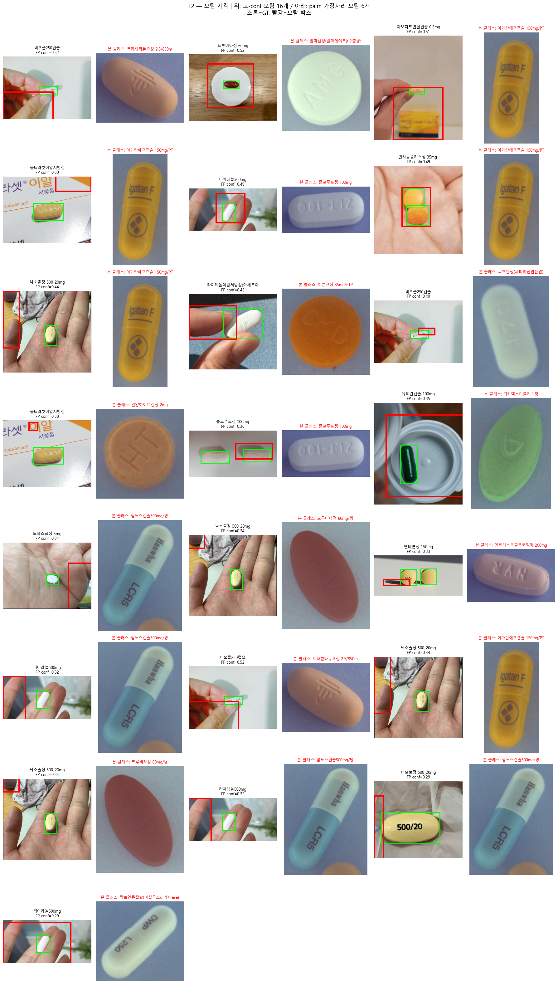


고-conf 오탐 (conf >= 0.3)
  1. 비오플250캡슐.png              conf=0.52 | 본 클래스: 트라젠타듀오정 2.5/850mg | env=palm edge=True
  2. 트루비타정 60mg.png            conf=0.52 | 본 클래스: 알마겔정(알마게이트)(수출명:유한가스트라겔정) | env=bottle edge=False
  3. 아보다트연질캡슐 0.5mg_1.png      conf=0.51 | 본 클래스: 이가탄에프캡슐 150mg/PTP | env=palm edge=False
  4. 울트라셋이알서방정.png             conf=0.50 | 본 클래스: 이가탄에프캡슐 150mg/PTP | env=box edge=True
  5. 타이레놀500mg.png             conf=0.49 | 본 클래스: 졸로푸트정 100mg | env=palm edge=False
  6. 인사돌플러스정 35mg_.png         conf=0.49 | 본 클래스: 이가탄에프캡슐 150mg/PTP | env=palm edge=False
  7. 낙소졸정 500_20mg.png         conf=0.44 | 본 클래스: 이가탄에프캡슐 150mg/PTP | env=palm edge=True
  8. 타이레놀이알서방정(아세트아미노펜)(수출용).p conf=0.42 | 본 클래스: 이튼큐정 35mg/PTP | env=palm edge=False
  9. 비오플250캡슐.png              conf=0.40 | 본 클래스: 씨즈날정(세티리진염산염) | env=palm edge=False
  10. 울트라셋이알서방정.png             conf=0.38 | 본 클래스: 일양하이트린정 2mg | env=box edge=True
  11. 졸로푸트정 100mg.png           conf=0.36 | 본 클래스: 졸로푸트정 100mg | env=paper edge=False
  12

In [23]:
# 1. 고-conf 오탐 (0.3 이상) — 자신만만한 오탐
high_conf_fp = df_fp[df_fp['top1_conf'] >= 0.3].sort_values('top1_conf', ascending=False).reset_index(drop=True)
print(f"고-conf 오탐 (conf >= 0.3): {len(high_conf_fp)}개")

# 2. palm 가장자리 오탐 샘플 (conf 높은 순 6개)
palm_edge_fp = df_fp[(df_fp['env'] == 'palm') & (df_fp['edge'])].sort_values('top1_conf', ascending=False).head(6).reset_index(drop=True)
print(f"palm 가장자리 오탐 샘플: {len(palm_edge_fp)}개")

def show_fp_case(ax_full, ax_pred, fp_row, results_data):
    """오탐 케이스 1개 시각화 (Test 이미지 + 예측 클래스 ROI)"""
    fname = fp_row['filename']
    img_data = next(d for d in results_data if d['filename'] == fname)
    
    # Test 이미지 전체 + 오탐 박스 + GT 박스
    img = imread_kr(TEST_IMAGES / fname)
    if img is None: return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax_full.imshow(img)
    
    # GT 박스 (초록)
    for gt in img_data['gt_bboxes']:
        gx1, gy1, gx2, gy2 = gt['bbox']
        ax_full.add_patch(Rectangle((gx1, gy1), gx2-gx1, gy2-gy1,
                                     linewidth=2, edgecolor='lime', facecolor='none'))
    
    # 오탐 박스 (빨강 굵게)
    pred = img_data['predictions'][int(fp_row['pred_idx'])]
    px1, py1, px2, py2 = pred['bbox']
    ax_full.add_patch(Rectangle((px1, py1), px2-px1, py2-py1,
                                 linewidth=3, edgecolor='red', facecolor='none'))
    
    short = fname.replace('.png', '')[:14]
    ax_full.set_title(f"{short}\nFP conf={fp_row['top1_conf']:.2f}", fontsize=9)
    ax_full.axis('off')
    
    # 모델이 본 K-code 샘플
    pred_name = fp_row['top1_pred']
    if pred_name and pred_name in samples_by_dl.index:
        s = samples_by_dl.loc[pred_name]
        if s['full_path'] is not None:
            roi = crop_pill_roi(s['full_path'],
                                 (s['bbox_x'], s['bbox_y'], s['bbox_w'], s['bbox_h']))
            if roi is not None:
                ax_pred.imshow(roi)
    ax_pred.set_title(f"본 클래스: {pred_name[:16] if pred_name else '?'}", fontsize=9, color='red')
    ax_pred.axis('off')


# 시각화: 고-conf 오탐 (위) + palm 가장자리 오탐 (아래)
high_n = len(high_conf_fp)
palm_n = len(palm_edge_fp)
total_cases = high_n + palm_n

cases_per_row = 3  # 3 케이스 per row, 2칸씩 → 6 cols
n_grid_cols = 6
nrows = (total_cases + cases_per_row - 1) // cases_per_row

fig, axes = plt.subplots(nrows, n_grid_cols, figsize=(n_grid_cols * 3, nrows * 4))
if nrows == 1: axes = axes.reshape(1, -1)

# 고-conf 오탐
for i, row in high_conf_fp.iterrows():
    grid_row = i // cases_per_row
    grid_col = (i % cases_per_row) * 2
    show_fp_case(axes[grid_row, grid_col], axes[grid_row, grid_col + 1], row, results['results'])

# palm 가장자리 오탐 (이어서)
for i, row in palm_edge_fp.iterrows():
    idx = high_n + i
    grid_row = idx // cases_per_row
    grid_col = (idx % cases_per_row) * 2
    show_fp_case(axes[grid_row, grid_col], axes[grid_row, grid_col + 1], row, results['results'])

# 빈 칸 정리
for i in range(total_cases, nrows * cases_per_row):
    grid_row = i // cases_per_row
    grid_col = (i % cases_per_row) * 2
    axes[grid_row, grid_col].axis('off')
    axes[grid_row, grid_col + 1].axis('off')

plt.suptitle(f"F2 — 오탐 시각 | 위: 고-conf 오탐 {high_n}개 / 아래: palm 가장자리 오탐 {palm_n}개\n"
             f"초록=GT, 빨강=오탐 박스",
             fontsize=13, y=1.00)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "08_fp_cases.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()

# 텍스트 요약
print("\n" + "=" * 80)
print("고-conf 오탐 (conf >= 0.3)")
print("=" * 80)
for i, row in high_conf_fp.iterrows():
    print(f"  {i+1}. {row['filename'][:25]:25s} conf={row['top1_conf']:.2f} | "
          f"본 클래스: {row['top1_pred']} | env={row['env']} edge={row['edge']}")

## E1 — 클래스별 정답률

검증:
- Test 등장 31개 클래스 중 잘 맞춤/못 맞춤 분포
- 클래스별 학습 데이터 양 (clean_df ann 수) vs 정답률 상관
- F2의 "특정 클래스 편향" 가설 검증

Test 등장 클래스: 31
Top-1 정답 클래스 (적어도 1번 맞춤): 11
Top-1 0% 클래스 (한 번도 못 맞춤): 20

모델이 예측에 사용한 고유 클래스: 75 (전체 118 중)

예측 빈도 Top 10 (TP+FP):
  엘스테인캡슐(에르도스테인)                        23회  (Test 등장: X)
  트루비타정 60mg/병                          18회  (Test 등장: O)
  이가탄에프캡슐 150mg/PTP                     14회  (Test 등장: X)
  알바스테인캡슐(에르도스테인)                       13회  (Test 등장: X)
  졸로푸트정 100mg                           12회  (Test 등장: O)
  람노스캡슐500mg/병                          11회  (Test 등장: X)
  메가파워정 90mg/병                          10회  (Test 등장: X)
  카발린캡슐 25mg                             9회  (Test 등장: X)
  씨즈날정(세티리진염산염)                          8회  (Test 등장: X)
  바이오탑하이캡슐 150mg/병                       8회  (Test 등장: X)

저장: D:\pill_detection\analysis\figures\09_class_acc.png


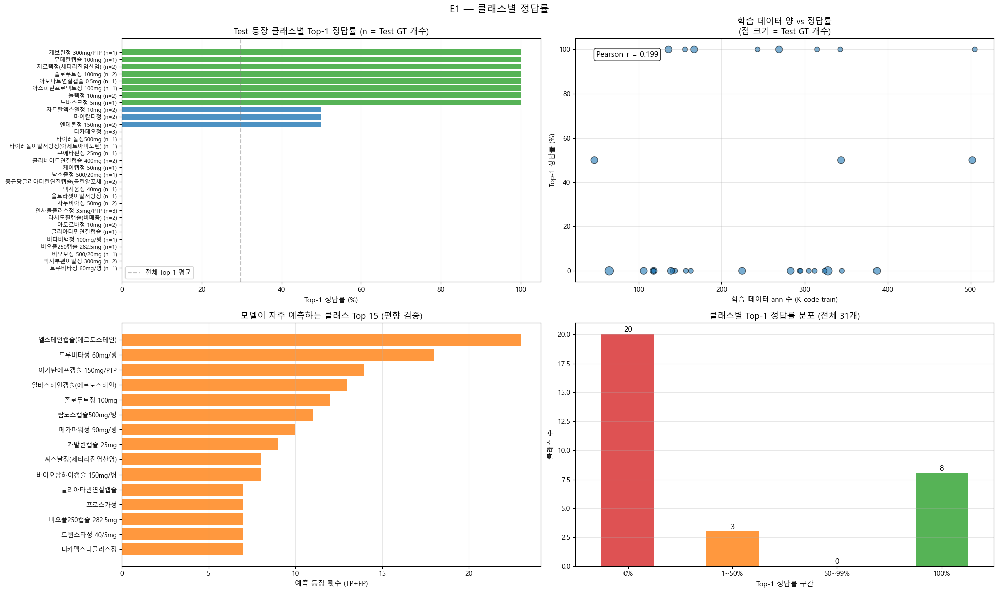


Test 등장 클래스별 상세 (정답률 정렬)
  게보린정 300mg/PTP                 | n= 1 | Top-1 1/1 (100.0%) | Top-3 1/1 (100.0%) | train_ann=315
  뮤테란캡슐 100mg                    | n= 1 | Top-1 1/1 (100.0%) | Top-3 1/1 (100.0%) | train_ann=156
  지르텍정(세티리진염산염)                  | n= 2 | Top-1 2/2 (100.0%) | Top-3 2/2 (100.0%) | train_ann=269
  졸로푸트정 100mg                    | n= 2 | Top-1 2/2 (100.0%) | Top-3 2/2 (100.0%) | train_ann=136
  아보다트연질캡슐 0.5mg                 | n= 1 | Top-1 1/1 (100.0%) | Top-3 1/1 (100.0%) | train_ann=243
  아스피린프로텍트정 100mg                | n= 1 | Top-1 1/1 (100.0%) | Top-3 1/1 (100.0%) | train_ann=505
  놀텍정 10mg                       | n= 2 | Top-1 2/2 (100.0%) | Top-3 2/2 (100.0%) | train_ann=167
  노바스크정 5mg                      | n= 1 | Top-1 1/1 (100.0%) | Top-3 1/1 (100.0%) | train_ann=343
  자트랄엑스엘정 10mg                   | n= 2 | Top-1 1/2 ( 50.0%) | Top-3 1/2 ( 50.0%) | train_ann= 47
  마이칼디정                          | n= 2 | Top-1 1/2 ( 50.0%) | Top-3 1/2 ( 50.0%) | train_an

In [24]:
# 클래스별 통계
class_stats = []
class_train_count = cdf['dl_name'].value_counts().to_dict()  # 전체 (train+val)
class_train_only_count = cdf[cdf['file_name'].isin(train_files)]['dl_name'].value_counts().to_dict()

# Test 등장 클래스
for dl_name in sorted(df_05['gt_name'].unique()):
    sub = df_05[df_05['gt_name'] == dl_name]
    n_gt = len(sub)
    n_top1 = (sub['verdict'] == 'top1').sum()
    n_top3 = sub['verdict'].isin(['top1', 'top3']).sum()
    n_det = sub['verdict'].isin(['top1', 'top3', 'det_only']).sum()
    
    class_stats.append({
        'dl_name': dl_name,
        'n_test_gt': n_gt,
        'n_top1': n_top1,
        'n_top3': n_top3,
        'n_det': n_det,
        'top1_pct': n_top1 / n_gt * 100,
        'top3_pct': n_top3 / n_gt * 100,
        'train_ann': class_train_only_count.get(dl_name, 0),
    })

df_cls = pd.DataFrame(class_stats).sort_values('top1_pct', ascending=False).reset_index(drop=True)
print(f"Test 등장 클래스: {len(df_cls)}")
print(f"Top-1 정답 클래스 (적어도 1번 맞춤): {(df_cls['n_top1'] > 0).sum()}")
print(f"Top-1 0% 클래스 (한 번도 못 맞춤): {(df_cls['n_top1'] == 0).sum()}")

# 모델 예측에 등장한 클래스 (오답 포함)
pred_class_count = {}
for _, row in df_05.iterrows():
    if row['top1_pred']:
        pred_class_count[row['top1_pred']] = pred_class_count.get(row['top1_pred'], 0) + 1
# 오탐(FP) Top-1 클래스도 합산
fp_pred_count = df_fp['top1_pred'].value_counts().to_dict()
all_pred_count = {**pred_class_count}
for k, v in fp_pred_count.items():
    all_pred_count[k] = all_pred_count.get(k, 0) + v

print(f"\n모델이 예측에 사용한 고유 클래스: {len(all_pred_count)} (전체 118 중)")
top10_pred = sorted(all_pred_count.items(), key=lambda x: -x[1])[:10]
print(f"\n예측 빈도 Top 10 (TP+FP):")
for name, cnt in top10_pred:
    in_test = name in set(df_05['gt_name'])
    print(f"  {name:35s} {cnt:4d}회  (Test 등장: {'O' if in_test else 'X'})")

# 시각화
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

# (1) 클래스별 Top-1 정답률 막대 (정렬)
ax = axes[0, 0]
df_plot = df_cls.copy()
colors = ['tab:green' if p == 100 else ('tab:blue' if p > 0 else 'tab:red')
          for p in df_plot['top1_pct']]
ax.barh(range(len(df_plot)), df_plot['top1_pct'], color=colors, alpha=0.8)
ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels([f"{n[:18]} (n={c})" for n, c in zip(df_plot['dl_name'], df_plot['n_test_gt'])],
                    fontsize=8)
ax.set_xlabel('Top-1 정답률 (%)')
ax.set_title('Test 등장 클래스별 Top-1 정답률 (n = Test GT 개수)')
ax.axvline(29.8, ls='--', color='gray', alpha=0.5, label='전체 Top-1 평균')
ax.invert_yaxis()
ax.legend(fontsize=9)
ax.grid(axis='x', alpha=0.3)

# (2) 학습 데이터 양 vs Top-1 정답률
ax = axes[0, 1]
ax.scatter(df_cls['train_ann'], df_cls['top1_pct'], 
           s=df_cls['n_test_gt']*50, alpha=0.6, c='tab:blue', edgecolors='k')
ax.set_xlabel('학습 데이터 ann 수 (K-code train)')
ax.set_ylabel('Top-1 정답률 (%)')
ax.set_title('학습 데이터 양 vs 정답률\n(점 크기 = Test GT 개수)')
# 상관계수
corr = df_cls[['train_ann', 'top1_pct']].corr().iloc[0, 1]
ax.text(0.05, 0.95, f"Pearson r = {corr:.3f}", transform=ax.transAxes,
        fontsize=11, va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.grid(alpha=0.3)

# (3) 예측 빈도 분포 — 모델이 어떤 클래스를 자주 부르는가
ax = axes[1, 0]
pred_freq = pd.Series(all_pred_count).sort_values(ascending=False).head(15)
ax.barh(range(len(pred_freq)), pred_freq.values, color='tab:orange', alpha=0.8)
ax.set_yticks(range(len(pred_freq)))
ax.set_yticklabels([f"{n[:25]}" for n in pred_freq.index], fontsize=9)
ax.set_xlabel('예측 등장 횟수 (TP+FP)')
ax.set_title('모델이 자주 예측하는 클래스 Top 15 (편향 검증)')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

# (4) Top-1 정답 분포 — 0%/0~50%/50~100%/100%
ax = axes[1, 1]
df_cls['top1_band'] = pd.cut(df_cls['top1_pct'], bins=[-1, 0.01, 50, 99.9, 101],
                              labels=['0%', '1~50%', '50~99%', '100%'])
band_counts = df_cls['top1_band'].value_counts().reindex(['0%', '1~50%', '50~99%', '100%'])
band_counts.plot(kind='bar', ax=ax,
                 color=['tab:red', 'tab:orange', 'tab:blue', 'tab:green'], alpha=0.8)
ax.set_ylabel('클래스 수')
ax.set_xlabel('Top-1 정답률 구간')
ax.set_title(f'클래스별 Top-1 정답률 분포 (전체 {len(df_cls)}개)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, v in enumerate(band_counts):
    ax.text(i, v + 0.2, str(v), ha='center', fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.suptitle("E1 — 클래스별 정답률", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "09_class_acc.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 요약
print("\n" + "=" * 80)
print("Test 등장 클래스별 상세 (정답률 정렬)")
print("=" * 80)
for _, row in df_cls.iterrows():
    print(f"  {row['dl_name'][:30]:30s} | n={row['n_test_gt']:2d} | "
          f"Top-1 {row['n_top1']}/{row['n_test_gt']} ({row['top1_pct']:5.1f}%) | "
          f"Top-3 {row['n_top3']}/{row['n_test_gt']} ({row['top3_pct']:5.1f}%) | "
          f"train_ann={row['train_ann']:3d}")

## G — 학습 곡선 (RTMDet-tiny 합성 통합본 7200)

검증:
- Train loss 정상 수렴 곡선인지
- Val mAP 천장 어디서 찍었는지 (조기 종료 가능했는지)
- Best epoch (15) 선택 적절한지

In [25]:
import json

SCALARS_PATH = Path(r"D:\wony98_work_dir\20260501_074043\vis_data\scalars.json")
print(f"scalars.json: {SCALARS_PATH.exists()}")

# scalars.json은 줄바꿈 구분 JSON (JSONL)
records = []
with open(SCALARS_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line:
            records.append(json.loads(line))

print(f"총 record 수: {len(records)}")
print(f"첫 record 키: {list(records[0].keys())}")
print(f"마지막 record 키: {list(records[-1].keys())}")

# train loss / val mAP 분리
train_records = [r for r in records if 'loss' in r]
val_records = [r for r in records if 'coco/bbox_mAP' in r or 'coco/bbox_mAP_50' in r]
print(f"\nTrain step 기록: {len(train_records)}")
print(f"Val 평가 기록: {len(val_records)}")

# 첫/마지막 train, val record 샘플
if train_records:
    print(f"\nTrain 첫 record: {train_records[0]}")
    print(f"Train 마지막 record: {train_records[-1]}")
if val_records:
    print(f"\nVal 첫 record: {val_records[0]}")
    print(f"Val 마지막 record: {val_records[-1]}")

scalars.json: True
총 record 수: 299
첫 record 키: ['base_lr', 'lr', 'data_time', 'loss', 'loss_cls', 'loss_bbox', 'time', 'epoch', 'iter', 'memory', 'step']
마지막 record 키: ['base_lr', 'lr', 'data_time', 'loss', 'loss_cls', 'loss_bbox', 'time', 'epoch', 'iter', 'memory', 'step']

Train step 기록: 285
Val 평가 기록: 14

Train 첫 record: {'base_lr': 1.2264639639639638e-05, 'lr': 1.2264639639639638e-05, 'data_time': 0.025862298011779784, 'loss': 2.768244156837463, 'loss_cls': 2.1002548861503603, 'loss_bbox': 0.6679892671108246, 'time': 0.30038325309753416, 'epoch': 1, 'iter': 50, 'memory': 5590, 'step': 50}
Train 마지막 record: {'base_lr': 0.000249999999999998, 'lr': 0.000249999999999998, 'data_time': 0.013560423851013184, 'loss': 0.3796029275655746, 'loss_cls': 0.23813857406377792, 'loss_bbox': 0.14146435141563415, 'time': 0.2629471206665039, 'epoch': 15, 'iter': 14516, 'memory': 5579, 'step': 14516}

Val 첫 record: {'coco/bbox_mAP': 0.683, 'coco/bbox_mAP_50': 0.753, 'coco/bbox_mAP_75': 0.745, 'coco/bbo

Val step (= epoch): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Train epoch 범위: 1 ~ 15

저장: D:\pill_detection\analysis\figures\10_training_curves.png


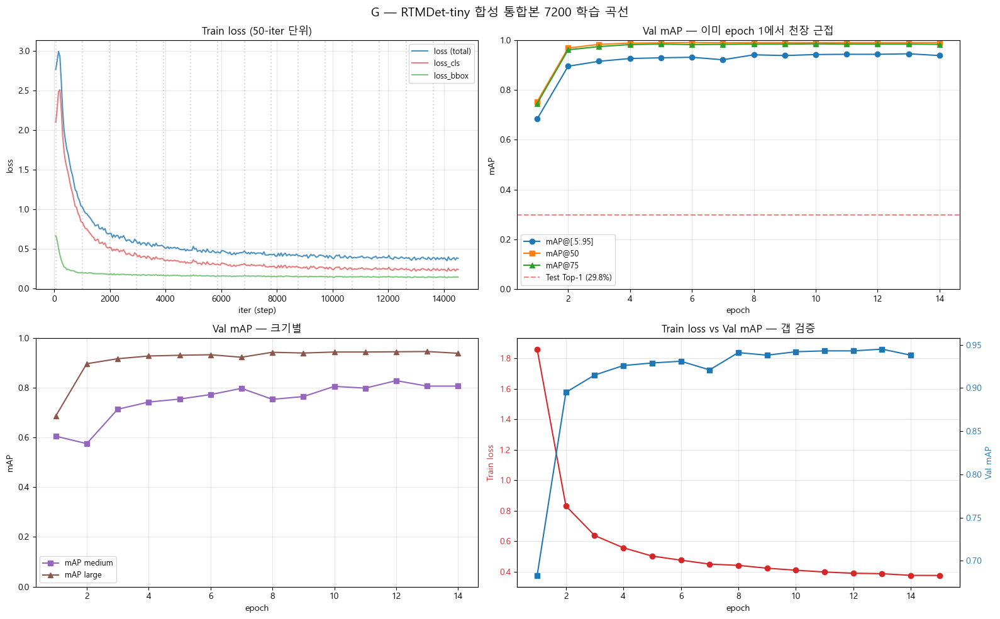


학습 곡선 요약

Val mAP 진행:
  epoch  1: mAP=0.683  mAP@50=0.753  mAP@75=0.745
  epoch  2: mAP=0.895  mAP@50=0.968  mAP@75=0.961
  epoch  3: mAP=0.915  mAP@50=0.983  mAP@75=0.974
  epoch  4: mAP=0.926  mAP@50=0.988  mAP@75=0.982
  epoch  5: mAP=0.929  mAP@50=0.989  mAP@75=0.984
  epoch  6: mAP=0.931  mAP@50=0.990  mAP@75=0.982
  epoch  7: mAP=0.921  mAP@50=0.989  mAP@75=0.983
  epoch  8: mAP=0.941  mAP@50=0.990  mAP@75=0.984
  epoch  9: mAP=0.938  mAP@50=0.990  mAP@75=0.984
  epoch 10: mAP=0.942  mAP@50=0.990  mAP@75=0.985
  epoch 11: mAP=0.943  mAP@50=0.990  mAP@75=0.984
  epoch 12: mAP=0.943  mAP@50=0.990  mAP@75=0.984
  epoch 13: mAP=0.945  mAP@50=0.990  mAP@75=0.984
  epoch 14: mAP=0.938  mAP@50=0.990  mAP@75=0.983

Best epoch: 13 (mAP=0.945)

Train loss 진행 (epoch별 평균):
  epoch  1: loss=1.860
  epoch  2: loss=0.832
  epoch  3: loss=0.638
  epoch  4: loss=0.557
  epoch  5: loss=0.503
  epoch  6: loss=0.476
  epoch  7: loss=0.450
  epoch  8: loss=0.442
  epoch  9: loss=0.423
  epoch 10: lo

In [26]:
# train: step 단위 / val: epoch 단위
train_df = pd.DataFrame(train_records)
val_df = pd.DataFrame(val_records)

# val step은 epoch 번호 (1~15)
print(f"Val step (= epoch): {val_df['step'].tolist()}")
print(f"Train epoch 범위: {train_df['epoch'].min()} ~ {train_df['epoch'].max()}")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# (1) Train total loss
ax = axes[0, 0]
ax.plot(train_df['step'], train_df['loss'], color='tab:blue', alpha=0.8, label='loss (total)')
ax.plot(train_df['step'], train_df['loss_cls'], color='tab:red', alpha=0.6, label='loss_cls')
ax.plot(train_df['step'], train_df['loss_bbox'], color='tab:green', alpha=0.6, label='loss_bbox')
# epoch 경계선
for e in train_df['epoch'].unique():
    e_step = train_df[train_df['epoch'] == e]['step'].iloc[0]
    ax.axvline(e_step, ls=':', color='gray', alpha=0.3)
ax.set_xlabel('iter (step)')
ax.set_ylabel('loss')
ax.set_title('Train loss (50-iter 단위)')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# (2) Val mAP / mAP@50 / mAP@75
ax = axes[0, 1]
ax.plot(val_df['step'], val_df['coco/bbox_mAP'], 'o-', label='mAP@[.5:.95]', color='tab:blue')
ax.plot(val_df['step'], val_df['coco/bbox_mAP_50'], 's-', label='mAP@50', color='tab:orange')
ax.plot(val_df['step'], val_df['coco/bbox_mAP_75'], '^-', label='mAP@75', color='tab:green')
ax.set_xlabel('epoch')
ax.set_ylabel('mAP')
ax.set_title('Val mAP — 이미 epoch 1에서 천장 근접')
ax.legend(fontsize=9)
ax.set_ylim(0, 1.0)
ax.grid(alpha=0.3)
# 전체 Top-1 정답률 (33장) 참조선
ax.axhline(0.298, ls='--', color='red', alpha=0.5, label='Test Top-1 (29.8%)')
ax.legend(fontsize=9)

# (3) Val mAP medium vs large (작은 알약은 -1.0이라 제외)
ax = axes[1, 0]
ax.plot(val_df['step'], val_df['coco/bbox_mAP_m'], 's-', label='mAP medium', color='tab:purple')
ax.plot(val_df['step'], val_df['coco/bbox_mAP_l'], '^-', label='mAP large', color='tab:brown')
ax.set_xlabel('epoch')
ax.set_ylabel('mAP')
ax.set_title('Val mAP — 크기별')
ax.legend(fontsize=9)
ax.set_ylim(0, 1.0)
ax.grid(alpha=0.3)

# (4) Val mAP vs Train loss (마지막 step 기준 epoch별)
ax = axes[1, 1]
# epoch별 train loss 평균
train_epoch_loss = train_df.groupby('epoch')['loss'].mean().reset_index()
val_epoch_map = val_df.copy()
val_epoch_map['epoch'] = val_epoch_map['step']

ax.plot(train_epoch_loss['epoch'], train_epoch_loss['loss'], 'o-',
        label='Train loss (avg)', color='tab:red')
ax.set_xlabel('epoch')
ax.set_ylabel('Train loss', color='tab:red')
ax.tick_params(axis='y', labelcolor='tab:red')

ax2 = ax.twinx()
ax2.plot(val_epoch_map['epoch'], val_epoch_map['coco/bbox_mAP'], 's-',
         label='Val mAP', color='tab:blue')
ax2.set_ylabel('Val mAP', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')
ax.set_title('Train loss vs Val mAP — 갭 검증')
ax.grid(alpha=0.3)

plt.suptitle("G — RTMDet-tiny 합성 통합본 7200 학습 곡선", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "10_training_curves.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 요약
print("\n" + "=" * 60)
print("학습 곡선 요약")
print("=" * 60)
print(f"\nVal mAP 진행:")
for _, row in val_df.iterrows():
    print(f"  epoch {int(row['step']):2d}: mAP={row['coco/bbox_mAP']:.3f}  mAP@50={row['coco/bbox_mAP_50']:.3f}  mAP@75={row['coco/bbox_mAP_75']:.3f}")

best_idx = val_df['coco/bbox_mAP'].idxmax()
print(f"\nBest epoch: {int(val_df.loc[best_idx, 'step'])} (mAP={val_df.loc[best_idx, 'coco/bbox_mAP']:.3f})")

print(f"\nTrain loss 진행 (epoch별 평균):")
for _, row in train_epoch_loss.iterrows():
    print(f"  epoch {int(row['epoch']):2d}: loss={row['loss']:.3f}")

# Val mAP vs Test Top-1 결정적 갭
print(f"\n결정적 갭:")
print(f"  Best Val mAP@50: {val_df['coco/bbox_mAP_50'].max():.3f}")
print(f"  Test Top-1 정답률: 0.298")
print(f"  → Val 0.99 vs Test 0.30 = 분포 갭 거의 모든 차이 설명")

## B3 — IoU 분포 (Detection 박스 정확도)

매칭된 47개 GT의 IoU 값 분포 확인. Detection 95.7% 안에서 박스가 얼마나 빡빡한지 / 헐거운지.

매칭된 GT: 45

IoU 통계:
count    45.000000
mean      0.832483
std       0.052415
min       0.698454
25%       0.806192
50%       0.824104
75%       0.885288
max       0.921621
Name: iou, dtype: float64

verdict별 IoU 평균:
              mean       std       min       max  count
verdict                                                
det_only  0.826907  0.059248  0.698454  0.910051     26
top1      0.840072  0.044022  0.768666  0.921621     14
top3      0.840232  0.038784  0.806192  0.891583      5


C:\Users\user\AppData\Local\Temp\ipykernel_12264\1005387297.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True)



저장: D:\pill_detection\analysis\figures\11_iou_distribution.png


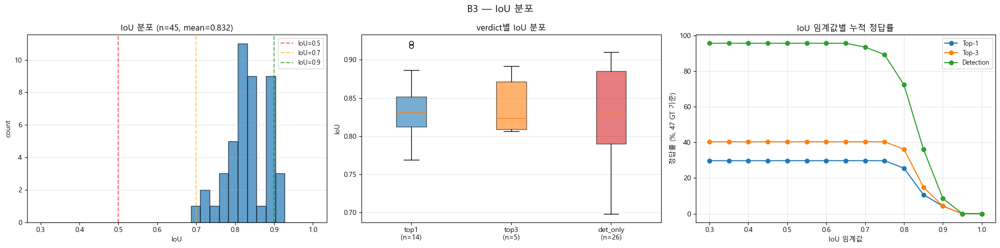


박스 정확도 등급 (n=45 매칭 케이스)
  매우 빡빡 (IoU >= 0.9)            :  4개 (  8.9%)
  빡빡 (0.8 <= IoU < 0.9)         : 30개 ( 66.7%)
  보통 (0.7 <= IoU < 0.8)         : 10개 ( 22.2%)
  헐거움 (0.5 <= IoU < 0.7)        :  1개 (  2.2%)
  매우 헐거움 (0.3 <= IoU < 0.5)     :  0개 (  0.0%)


In [27]:
# 매칭된 GT만 (det_fail 제외)
df_iou = df_05[df_05['pred_idx'].notna()].copy()
df_iou['iou'] = df_iou['iou'].astype(float)

print(f"매칭된 GT: {len(df_iou)}")
print(f"\nIoU 통계:")
print(df_iou['iou'].describe())

# verdict별 IoU 분포
print(f"\nverdict별 IoU 평균:")
print(df_iou.groupby('verdict')['iou'].agg(['mean', 'std', 'min', 'max', 'count']))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# (1) 전체 IoU 히스토그램
ax = axes[0]
bins = np.linspace(0.3, 1.0, 30)
ax.hist(df_iou['iou'], bins=bins, alpha=0.7, color='tab:blue', edgecolor='black')
for thr, c in [(0.5, 'red'), (0.7, 'orange'), (0.9, 'green')]:
    ax.axvline(thr, ls='--', color=c, alpha=0.6, label=f'IoU={thr}')
ax.set_xlabel('IoU')
ax.set_ylabel('count')
ax.set_title(f'IoU 분포 (n={len(df_iou)}, mean={df_iou["iou"].mean():.3f})')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# (2) verdict별 IoU boxplot
ax = axes[1]
verdict_order = ['top1', 'top3', 'det_only']
data = [df_iou[df_iou['verdict'] == v]['iou'].values for v in verdict_order]
labels = [f"{v}\n(n={(df_iou['verdict']==v).sum()})" for v in verdict_order]
bp = ax.boxplot(data, labels=labels, patch_artist=True)
for patch, c in zip(bp['boxes'], ['tab:blue', 'tab:orange', 'tab:red']):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)
ax.set_ylabel('IoU')
ax.set_title('verdict별 IoU 분포')
ax.grid(axis='y', alpha=0.3)

# (3) IoU 임계값별 누적 정답률
ax = axes[2]
thresholds = np.arange(0.3, 1.01, 0.05)
for v_set, label, color in [
    ({'top1'}, 'Top-1', 'tab:blue'),
    ({'top1', 'top3'}, 'Top-3', 'tab:orange'),
    ({'top1', 'top3', 'det_only'}, 'Detection', 'tab:green'),
]:
    pcts = []
    for thr in thresholds:
        n_match = ((df_iou['iou'] >= thr) & (df_iou['verdict'].isin(v_set))).sum()
        pcts.append(n_match / 47 * 100)  # 전체 47 GT 기준
    ax.plot(thresholds, pcts, 'o-', label=label, color=color)
ax.set_xlabel('IoU 임계값')
ax.set_ylabel('정답률 (%, 47 GT 기준)')
ax.set_title('IoU 임계값별 누적 정답률')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.suptitle("B3 — IoU 분포", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "11_iou_distribution.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 요약 — 박스 정확도 등급
print("\n" + "=" * 60)
print("박스 정확도 등급 (n=45 매칭 케이스)")
print("=" * 60)
for thr_lo, thr_hi, label in [
    (0.9, 1.01, "매우 빡빡 (IoU >= 0.9)"),
    (0.8, 0.9, "빡빡 (0.8 <= IoU < 0.9)"),
    (0.7, 0.8, "보통 (0.7 <= IoU < 0.8)"),
    (0.5, 0.7, "헐거움 (0.5 <= IoU < 0.7)"),
    (0.3, 0.5, "매우 헐거움 (0.3 <= IoU < 0.5)"),
]:
    n = ((df_iou['iou'] >= thr_lo) & (df_iou['iou'] < thr_hi)).sum()
    print(f"  {label:30s}: {n:2d}개 ({n/len(df_iou)*100:5.1f}%)")

## E3 — Top-3 회복 케이스 시각

Top-1은 틀렸지만 Top-3 안에 정답 들어간 케이스 5개 (verdict=top3).

분류기가 후보군에 정답 넣었지만 1순위로 못 올린 패턴 분석:
- 정답 vs Top-1 예측 vs Top-2/3 예측 ROI 비교
- Top-1 conf vs 정답 클래스 conf 갭 측정

Top-3 회복 케이스: 5개
  1. 라시도필캡슐(비매품).png           GT=라시도필캡슐(비매품)         
     Top-3: [('카발린캡슐 25mg', 0.428), ('한미탐스캡슐 0.2mg', 0.391), ('라시도필캡슐(비매품)', 0.358)]
  2. 라시도필캡슐(비매품).png           GT=라시도필캡슐(비매품)         
     Top-3: [('카발린캡슐 25mg', 0.577), ('졸로푸트정 100mg', 0.255), ('라시도필캡슐(비매품)', 0.247)]
  3. 비모보정 500_20mg.png         GT=비모보정 500/20mg       
     Top-3: [('바이오탑하이캡슐 150mg/병', 0.653), ('글리틴정(콜린알포세레이트)', 0.222), ('비모보정 500/20mg', 0.187)]
  4. 엔테론정 150mg.png            GT=엔테론정 150mg          
     Top-3: [('자트랄엑스엘정 10mg', 0.473), ('쎄로켈정 100mg', 0.377), ('엔테론정 150mg', 0.319)]
  5. 자누비아정 50mg.png            GT=자누비아정 50mg          
     Top-3: [('삼남건조수산화알루미늄겔정', 0.486), ('제라타딘정(로라타딘)', 0.398), ('자누비아정 50mg', 0.27)]


C:\Users\user\AppData\Local\Temp\ipykernel_12264\2492262110.py:61: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_12264\2492262110.py:63: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  plt.savefig(out_path, dpi=120, bbox_inches='tight')



저장: D:\pill_detection\analysis\figures\12_top3_recovery.png


d:\pill_detection\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


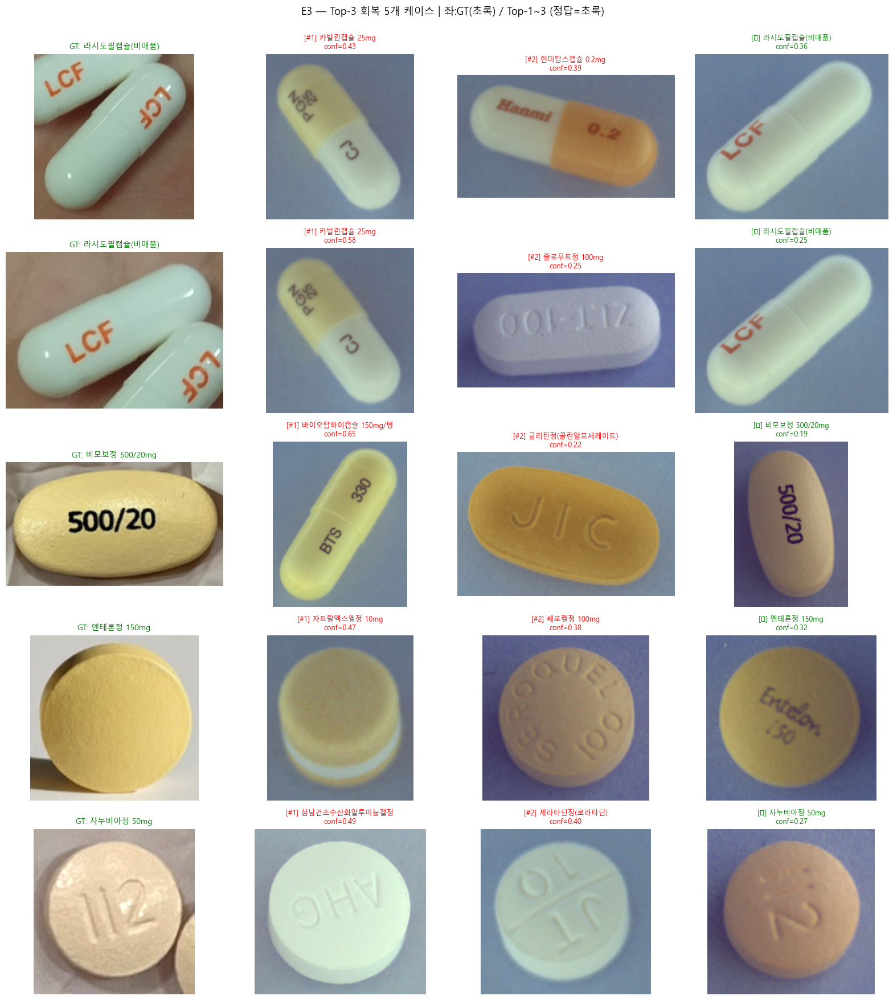


Top-3 회복 케이스 — conf 갭 분석

1. 라시도필캡슐(비매품).png
   GT: 라시도필캡슐(비매품)
   Top-1: 카발린캡슐 25mg (conf=0.428)
   정답 순위: #3 (conf=0.358)
   conf 갭 (Top-1 - 정답): 0.070

2. 라시도필캡슐(비매품).png
   GT: 라시도필캡슐(비매품)
   Top-1: 카발린캡슐 25mg (conf=0.577)
   정답 순위: #3 (conf=0.247)
   conf 갭 (Top-1 - 정답): 0.330

3. 비모보정 500_20mg.png
   GT: 비모보정 500/20mg
   Top-1: 바이오탑하이캡슐 150mg/병 (conf=0.653)
   정답 순위: #3 (conf=0.187)
   conf 갭 (Top-1 - 정답): 0.466

4. 엔테론정 150mg.png
   GT: 엔테론정 150mg
   Top-1: 자트랄엑스엘정 10mg (conf=0.473)
   정답 순위: #3 (conf=0.319)
   conf 갭 (Top-1 - 정답): 0.155

5. 자누비아정 50mg.png
   GT: 자누비아정 50mg
   Top-1: 삼남건조수산화알루미늄겔정 (conf=0.486)
   정답 순위: #3 (conf=0.270)
   conf 갭 (Top-1 - 정답): 0.216


In [29]:
top3_cases = df_05[df_05['verdict'] == 'top3'].reset_index(drop=True)
print(f"Top-3 회복 케이스: {len(top3_cases)}개")

# top3_conf는 results['results']에서 직접 가져옴
def get_pred_top3(fname, pred_idx):
    img_data = next(d for d in results['results'] if d['filename'] == fname)
    pred = img_data['predictions'][int(pred_idx)]
    return pred.get('top3_class_name', []), pred.get('top3_confidence', [])

for i, row in top3_cases.iterrows():
    names, confs = get_pred_top3(row['filename'], row['pred_idx'])
    print(f"  {i+1}. {row['filename'][:25]:25s} GT={row['gt_name'][:20]:20s}")
    print(f"     Top-3: {list(zip(names, [round(c, 3) for c in confs]))}")

n_cases = len(top3_cases)
fig, axes = plt.subplots(n_cases, 4, figsize=(16, n_cases * 3.5))
if n_cases == 1:
    axes = axes.reshape(1, -1)

for i, row in top3_cases.iterrows():
    fname = row['filename']
    img_data = next(d for d in results['results'] if d['filename'] == fname)
    
    # GT ROI
    ax = axes[i, 0]
    gt_bbox = img_data['gt_bboxes'][int(row['gt_idx'])]['bbox']
    gt_roi = crop_test_roi(TEST_IMAGES / fname, gt_bbox)
    if gt_roi is not None:
        ax.imshow(gt_roi)
    ax.set_title(f"GT: {row['gt_name'][:18]}", fontsize=10, color='green')
    ax.axis('off')
    
    # Top-1, 2, 3
    top3_names, top3_conf = get_pred_top3(fname, row['pred_idx'])
    gt_name = row['gt_name']
    
    for k in range(3):
        ax = axes[i, k + 1]
        if k < len(top3_names):
            pred_name = top3_names[k]
            conf = top3_conf[k]
            
            if pred_name in samples_by_dl.index:
                s = samples_by_dl.loc[pred_name]
                if s['full_path'] is not None:
                    pred_roi = crop_pill_roi(
                        s['full_path'],
                        (s['bbox_x'], s['bbox_y'], s['bbox_w'], s['bbox_h'])
                    )
                    if pred_roi is not None:
                        ax.imshow(pred_roi)
            
            color = 'green' if pred_name == gt_name else 'red'
            marker = '✓' if pred_name == gt_name else f'#{k+1}'
            ax.set_title(f"[{marker}] {pred_name[:16]}\nconf={conf:.2f}",
                         fontsize=9, color=color)
        ax.axis('off')

plt.suptitle(f"E3 — Top-3 회복 {n_cases}개 케이스 | 좌:GT(초록) / Top-1~3 (정답=초록)",
             fontsize=13, y=1.00)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "12_top3_recovery.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# conf 갭 분석
print("\n" + "=" * 80)
print("Top-3 회복 케이스 — conf 갭 분석")
print("=" * 80)
for i, row in top3_cases.iterrows():
    gt_name = row['gt_name']
    top3_names, top3_conf = get_pred_top3(row['filename'], row['pred_idx'])
    
    top1_conf = top3_conf[0]
    gt_rank = top3_names.index(gt_name) + 1
    gt_conf = top3_conf[gt_rank - 1]
    conf_gap = top1_conf - gt_conf
    
    print(f"\n{i+1}. {row['filename'][:30]}")
    print(f"   GT: {gt_name}")
    print(f"   Top-1: {top3_names[0]} (conf={top1_conf:.3f})")
    print(f"   정답 순위: #{gt_rank} (conf={gt_conf:.3f})")
    print(f"   conf 갭 (Top-1 - 정답): {conf_gap:.3f}")

## 핀 클래스 K-code ROI 시각

E1에서 모델이 자주 예측한 Top 10 중 Test에 등장 안 한 6개 클래스:
- 엘스테인캡슐(에르도스테인) — 23회
- 이가탄에프캡슐 150mg/PTP — 14회
- 알바스테인캡슐(에르도스테인) — 13회
- 람노스캡슐500mg/병 — 11회
- 메가파워정 90mg/병 — 10회
- 카발린캡슐 25mg — 9회

학습 데이터 K-code ROI 시각으로 **왜 모델이 이걸로 핀 박혔나** 데이터 확인.

핀 클래스 (Test 등장 X, 예측 빈도 높은 순):
  엘스테인캡슐(에르도스테인)                      예측  23회 / train_ann 322
  이가탄에프캡슐 150mg/PTP                   예측  14회 / train_ann 450
  알바스테인캡슐(에르도스테인)                     예측  13회 / train_ann 278
  람노스캡슐500mg/병                        예측  11회 / train_ann 295
  메가파워정 90mg/병                        예측  10회 / train_ann 320
  카발린캡슐 25mg                          예측   9회 / train_ann 116

비교군 — 100% 정답 클래스 6개:
  게보린정 300mg/PTP                      예측   3회 / train_ann 315
  뮤테란캡슐 100mg                         예측   2회 / train_ann 156
  지르텍정(세티리진염산염)                       예측   2회 / train_ann 269
  졸로푸트정 100mg                         예측  12회 / train_ann 136
  아보다트연질캡슐 0.5mg                      예측   1회 / train_ann 243
  아스피린프로텍트정 100mg                     예측   1회 / train_ann 505

저장: D:\pill_detection\analysis\figures\13_pin_classes.png


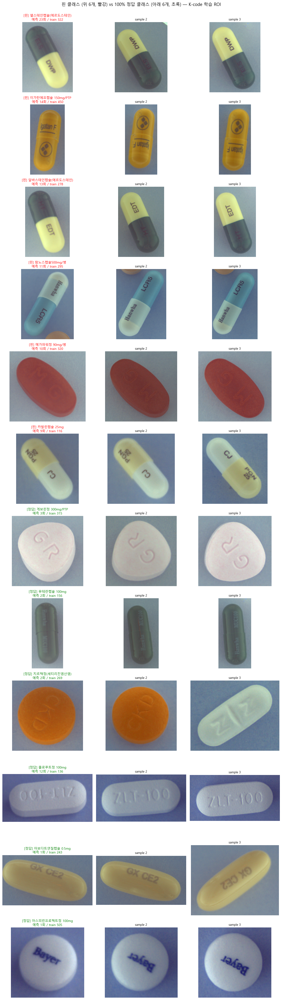


핀 클래스 vs 100% 정답 클래스 — train_ann 비교
핀 클래스 train_ann: mean=297, min=116, max=450
정답 클래스 train_ann: mean=271, min=136, max=505


In [30]:
# 핀 클래스 (예측 빈도 Top, Test 등장 X)
test_dl_set = set(df_05['gt_name'].unique())
pin_classes = []
for name, cnt in sorted(all_pred_count.items(), key=lambda x: -x[1])[:15]:
    if name not in test_dl_set:
        pin_classes.append((name, cnt))
    if len(pin_classes) >= 6:
        break

print("핀 클래스 (Test 등장 X, 예측 빈도 높은 순):")
for name, cnt in pin_classes:
    train_ann = class_train_only_count.get(name, 0)
    print(f"  {name:35s} 예측 {cnt:3d}회 / train_ann {train_ann:3d}")

# 비교군: Test 등장 + 100% 정답 클래스 (잘 맞춘 클래스 — 시각 비교용)
correct_classes = df_cls[df_cls['top1_pct'] == 100]['dl_name'].tolist()[:6]
print(f"\n비교군 — 100% 정답 클래스 6개:")
for name in correct_classes:
    train_ann = class_train_only_count.get(name, 0)
    pred_cnt = all_pred_count.get(name, 0)
    print(f"  {name:35s} 예측 {pred_cnt:3d}회 / train_ann {train_ann:3d}")

# 시각화 — 각 클래스마다 K-code 샘플 3장 (다른 file)
def get_n_samples_for_dl(dl_name, n=3):
    """한 dl_name에 대해 다른 파일 n개 샘플"""
    sub = cdf_exist[cdf_exist['dl_name'] == dl_name]
    sub = sub.drop_duplicates(subset='file_name')
    return sub.head(n)

n_classes = len(pin_classes) + len(correct_classes)
n_samples_per = 3
fig, axes = plt.subplots(n_classes, n_samples_per, figsize=(n_samples_per * 4, n_classes * 3.5))

# 핀 클래스 (위)
for i, (name, cnt) in enumerate(pin_classes):
    samples = get_n_samples_for_dl(name, n_samples_per)
    train_ann = class_train_only_count.get(name, 0)
    
    for k, (_, s) in enumerate(samples.iterrows()):
        ax = axes[i, k]
        path = find_path(s['file_name'])
        if path:
            roi = crop_pill_roi(path, (s['bbox_x'], s['bbox_y'], s['bbox_w'], s['bbox_h']))
            if roi is not None:
                ax.imshow(roi)
        if k == 0:
            ax.set_title(f"[핀] {name[:20]}\n예측 {cnt}회 / train {train_ann}",
                         fontsize=10, color='red')
        else:
            ax.set_title(f"sample {k+1}", fontsize=9)
        ax.axis('off')

# 비교군 (아래)
for i, name in enumerate(correct_classes):
    row_idx = len(pin_classes) + i
    samples = get_n_samples_for_dl(name, n_samples_per)
    train_ann = class_train_only_count.get(name, 0)
    pred_cnt = all_pred_count.get(name, 0)
    
    for k, (_, s) in enumerate(samples.iterrows()):
        ax = axes[row_idx, k]
        path = find_path(s['file_name'])
        if path:
            roi = crop_pill_roi(path, (s['bbox_x'], s['bbox_y'], s['bbox_w'], s['bbox_h']))
            if roi is not None:
                ax.imshow(roi)
        if k == 0:
            ax.set_title(f"[정답] {name[:20]}\n예측 {pred_cnt}회 / train {train_ann}",
                         fontsize=10, color='green')
        else:
            ax.set_title(f"sample {k+1}", fontsize=9)
        ax.axis('off')

plt.suptitle(f"핀 클래스 (위 6개, 빨강) vs 100% 정답 클래스 (아래 6개, 초록) — K-code 학습 ROI",
             fontsize=13, y=1.00)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures" / "13_pin_classes.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

# 정량 비교
print("\n" + "=" * 60)
print("핀 클래스 vs 100% 정답 클래스 — train_ann 비교")
print("=" * 60)
pin_train = [class_train_only_count.get(n, 0) for n, _ in pin_classes]
correct_train = [class_train_only_count.get(n, 0) for n in correct_classes]
print(f"핀 클래스 train_ann: mean={np.mean(pin_train):.0f}, "
      f"min={min(pin_train)}, max={max(pin_train)}")
print(f"정답 클래스 train_ann: mean={np.mean(correct_train):.0f}, "
      f"min={min(correct_train)}, max={max(correct_train)}")

# 종합 진단 요약 — RTMDet-tiny 합성 통합본 7200 (Top-1 29.8%)

## 검증 데이터
- Test 33장 / 47 GT / 31 클래스 등장
- 학습 곡선 (scalars.json), K-code 학습 ROI, 양질/신규 합성 분포

## 핵심 결론

### 학습/모델 무죄
- Val mAP@50 = 0.99 / Val mAP@[.5:.95] = 0.945 (best epoch 13)
- Train loss 매끄럽게 단조 감소 (1.86 → 0.38)
- Detection 박스 IoU 평균 0.832 (75.6%가 IoU >= 0.8)
- → **모델은 자기 학습 분포는 거의 완벽 해결**

### Test 30% 원인 = 학습 분포가 좁아서 일반화 안 됨
- Val 0.99 vs Test Top-1 0.298 → **70pp 갭**
- Detection 95.7% (박스 단계는 일반화 OK)
- 분류 단계에서 학습 분포 밖 케이스를 못 풀어냄
- 모델이 시각 신호(색·형태)에만 의존 — 처음 보는 환경/알약에서 작동 못 함

## 검증된 7대 문제

| 순위 | 문제 | 근거 |
|---|---|---|
| 1 | 학습 분포 자체가 좁음 | G — Val 0.99 vs Test 0.30 |
| 2 | 핀 클래스 hallucination (특정 캡슐 6개로 단축경로) | E1 — 예측 빈도 Top 6/10이 Test 0회 / 학습 ann과 무관 (r=0.199) |
| 3 | 각인 학습 실패 | B+E2, E3, 핀 클래스 ROI — 각인 또렷한데 색·형태로만 분류 |
| 4 | 단일 알약 학습 다양성 부족 | D4 — 합성 1개 비율 3.4% (1개 케이스 거의 학습 X) |
| 5 | palm 환경 + 손/손가락 오탐 | C + F2 — palm 정답률 25%, 손가락 끝을 알약으로 오인 |
| 6 | 알약 크기 분포 폭이 좁음 | D3 + 추가 측정 — 신규 합성 std 0.251 vs 양질 std 0.586 |
| 7 | 클래스 정답률 양극화 | E1 — 50~99% 0개, 0% 64.5%, 100% 25.8% |

## 부정된 가설

| 가설 | 근거 |
|---|---|
| 격자 외우기 (Detection 단계 영향) | D2 — 매칭 예측 4모드 0% (K-code 90.6% vs 모델 0%) |
| 배경 단조로움 직접 영향 | D2 + G — Detection은 다양 환경 OK |
| 학습 데이터 양 부족 | E1 — train_ann × 정답률 r=0.199 / 핀 클래스 평균 297 vs 정답 클래스 평균 271 |
| 학습 설정/모델 문제 | G — Val mAP@50 0.99 |
| 알약 크기 평균 갭 | 합성/Test 모두 정규화 면적 평균 log -1.23. 평균은 갭 없고, 진짜 차별점은 분포 폭(std). 이전 진단의 "합성 -3~-5" 표현은 측정 오류로 정정 |

## 핀 클래스 (시각 신호 단축경로)

엘스테인캡슐(23) / 이가탄에프캡슐(14) / 알바스테인캡슐(13) / 람노스캡슐(11) / 메가파워정(10) / 카발린캡슐(9)

**6개 모두 캡슐/타원 형태**. 모델이 각인을 학습 신호로 못 쓰고 시각 신호(색·형태)에만 의존한 결과 — 캡슐 형태 보이면 이 6개 중 하나로 분류. 손가락 끝, 약통 빈 공간, 박스 모서리도 같은 패턴으로 오탐. 환경 무관 발생.

## 환경별 정답률

| 환경 | n | Top-1 |
|---|---|---|
| paper | 7 | 57.1% |
| bottle | 2 | 50.0% |
| cloth | 10 | 30.0% |
| palm | 20 | 25.0% |
| desk | 5 | 20.0% |
| dark | 2 | 0% |

학습 데이터(K-code)가 단조 배경 + 4개 격자 위주라, 그 분포에서 멀어진 환경일수록 정답률 떨어짐.

## 처방 (일반화 초점, 우선순위)

| 순위 | 처방 | 검증 근거 |
|---|---|---|
| 1 | 학습 입력 해상도 1024 이상 (각인 학습 핵심) | E1, B+E2, 핀 클래스 ROI — 각인 미학습 |
| 2 | 합성 알약 크기 분포 폭 확대 (양방향 스케일) | D3 + 추가 측정 — 신규 std 0.251 / 양질 0.586 |
| 3 | 합성 알약 개수 다양성 (1~5개 골고루) | D4 — 합성 1개 비율 3.4% |
| 4 | palm 배경 다양화 + 손/손가락 합성 | C + F2 — 손가락 오탐 |

이전 처방의 "118 클래스 균형"은 제외 — 합성 코드가 이미 클래스 균등 샘플링. 핀 클래스 문제는 처방 1+2의 각인 학습 살아나면 자연 해소 예상.

## 데이터 기준점

- 합성 통합본 7200/800 학습: Val mAP@50 0.99 / Test Top-1 29.8% / Top-3 40.4%
- Detection: 95.7% / IoU mean 0.832
- 오탐 259개 (mean conf 0.116, 가장자리 73.4%)
- 학습 시간: 14,516 iter / 15 epoch / GPU A100
- Best epoch: 13

## 산출물 (analysis/figures)

01_grid_33images / 02_pred_center_distribution / 03_bbox_size_vs_verdict / 
04_pill_count_vs_verdict / 05_env_vs_verdict / 06_confusion_pairs / 
07_fp_analysis / 08_fp_cases / 09_class_acc / 10_training_curves / 
11_iou_distribution / 12_top3_recovery / 13_pin_classes